In [180]:
from skimage.io import imread
from skimage.transform import downscale_local_mean,rescale
from bioio import BioImage
img_j23 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Camille\230226\Insert_1.czi")
img_j23 = rescale(img_j23.data[0,:,0],0.1,channel_axis=0)
# img_j23 = img_j23.data[0,:,0]
img_j24 = imread(r"C:\Users\Emman\Desktop\work\These\Code\Stitcher\data\output\Insert_1_J24.tif")
img_j24 = rescale(img_j24,0.1,channel_axis = 0)

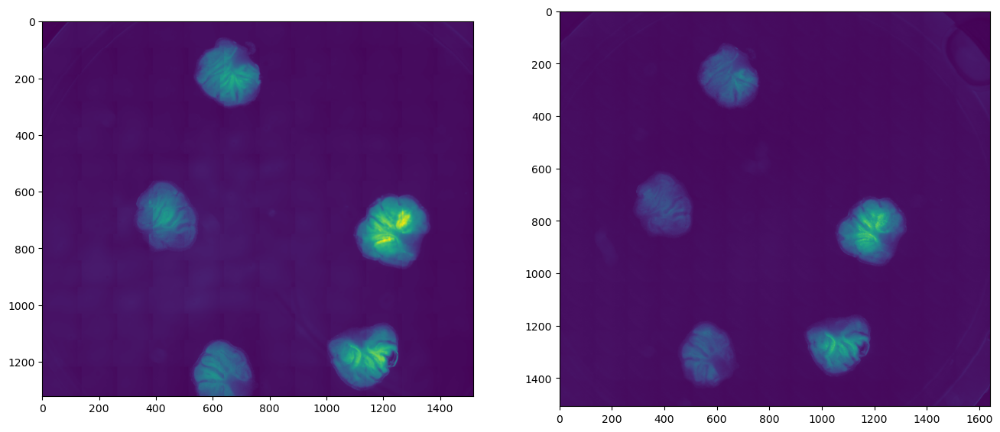

In [181]:
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(img_j23[0])
ax[1].imshow(img_j24[0])

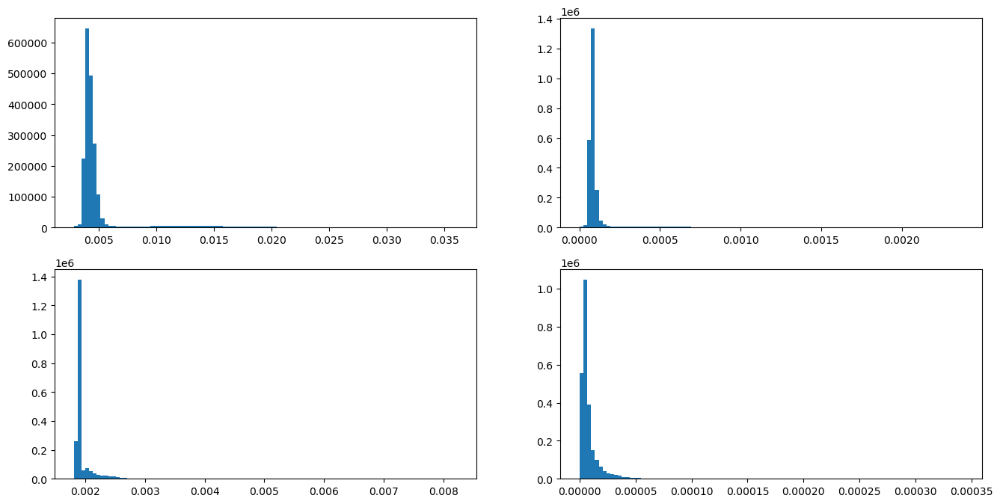

In [182]:
from skimage.filters import threshold_otsu as thresh
import matplotlib.pyplot as plt
fig,ax = plt.subplots(2,2,figsize=(16,8))
_ = ax[0,0].hist(img_j23[0].flatten(),bins=100)
_ = ax[0,1].hist(img_j24[0].flatten(),bins=100)
_ = ax[1,0].hist(img_j23[1].flatten(),bins=100)
_ = ax[1,1].hist(img_j24[1].flatten(),bins=100)

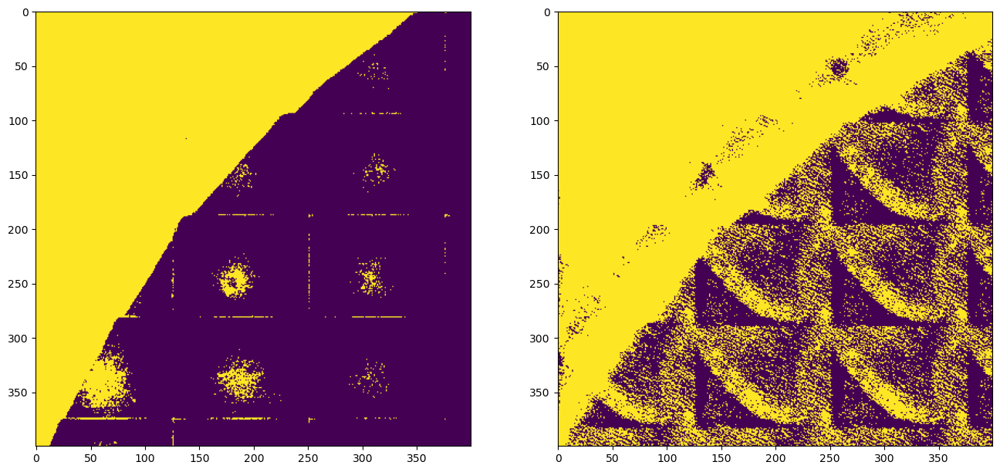

In [59]:
from skimage.filters import threshold_otsu as thresh
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2,figsize=(16,8))
crop_1 = img_j23[1,:400,:400]>0.00191630
crop_2 = img_j24[1,:400,:400]>0.000005
ax[0].imshow(crop_1)
ax[1].imshow(crop_2)

Detected rotation angle: -68.60 degrees
Detected translation shift (Y, X): [ 0.  63.5]


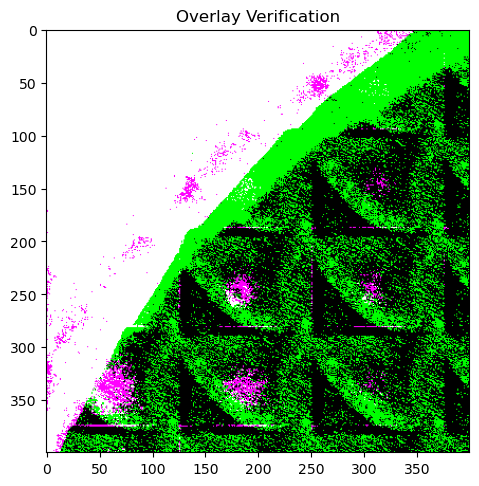

In [ ]:
from skimage.registration import phase_cross_correlation
from skimage.transform import warp_polar, rotate
from skimage.filters import gaussian
import numpy as np
import matplotlib.pyplot as plt

# 1. Pre-process: Smoothing is CRITICAL for noisy binary images
# It creates gradients that phase correlation can 'lock' onto.
sigma = 3 
img1_s = gaussian(crop_1, sigma=sigma)
img2_s = gaussian(crop_2, sigma=sigma)

# 2. Detect Rotation
# We transform images to polar coordinates around the center.
radius = min(img1_s.shape) / 2
img1_p = warp_polar(img1_s, radius=radius)
img2_p = warp_polar(img2_s, radius=radius)

# A rotation in X-Y becomes a translation in Polar coords (theta axis).
# We find the shift in the polar domain.1
polar_shift, _, _ = phase_cross_correlation(img1_p, img2_p, upsample_factor=10)

# Calculate angle in degrees
angle = (polar_shift[0] * 360) / img1_p.shape[0]
print(f"Detected rotation angle: {angle:.2f} degrees")

# 3. Detect Translation
# Rotate img2 by the detected angle, then find translation shift.
img2_rotated = rotate(img2_s, angle)
shift, _, _ = phase_cross_correlation(img1_s, img2_rotated, upsample_factor=10)

print(f"Detected translation shift (Y, X): {shift}")

# 4. Verification Overlay
from scipy.ndimage import shift as nd_shift
# Apply both rotation and translation to the original raw mask
img2_final = nd_shift(rotate(crop_2, 0), 0)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(np.stack([crop_1.astype(float), img2_final,crop_1.astype(float)], axis=2))
plt.title("Overlay Verification")
plt.show()

In [75]:
img_j23.shape,img_j24.shape

((2, 1321, 1517), (2, 1508, 1642))

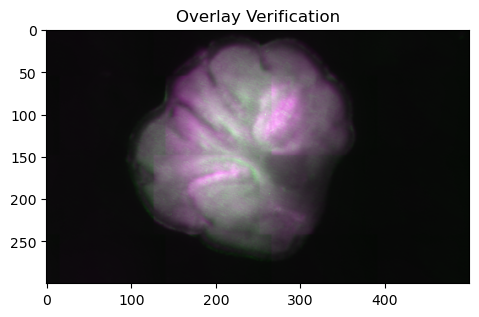

In [136]:
from skimage.exposure import rescale_intensity
from skimage.transform import rotate
# 4. Verification Overlay
from scipy.ndimage import shift as nd_shift
# Apply both rotation and translation to the original raw mask

img_1 = rescale_intensity(img_j23[0],in_range=(img_j23[0].min(),img_j23[0].max()),out_range=(0,1))#>0.00191630
img_1 = img_1.astype(float)
img_2 = img_j24[0]#>0.000005
img2_final = nd_shift(rotate(img_2,3), (-80,40))
img2_final = img2_final[:1321,:1517]
img2_final = rescale_intensity(img2_final,in_range=(img2_final.min(),img2_final.max()),out_range=(0,1))
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(np.stack([img_1.astype(float), img2_final,img_1.astype(float)], axis=2)[600:900,1000:1500])
plt.title("Overlay Verification")
plt.show()

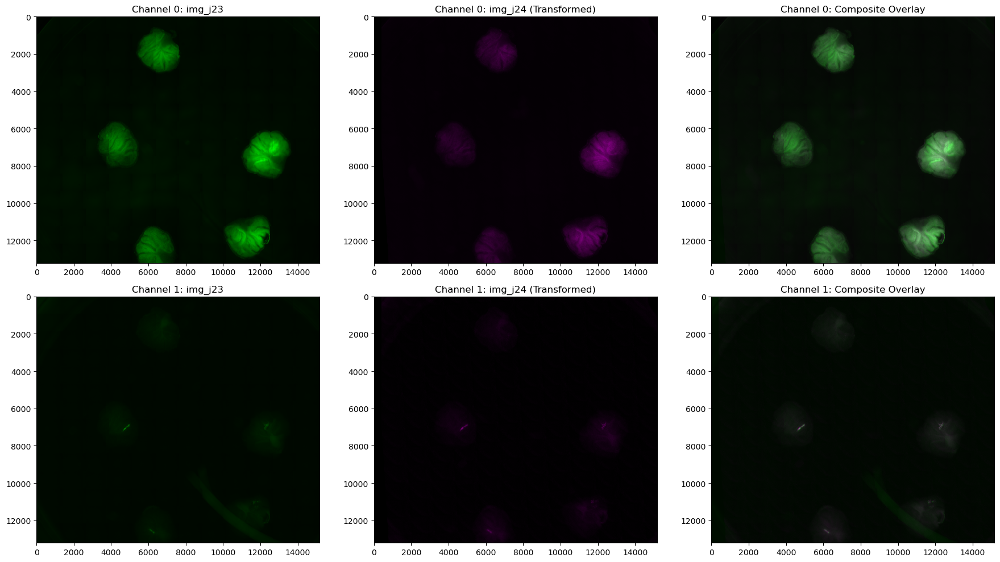

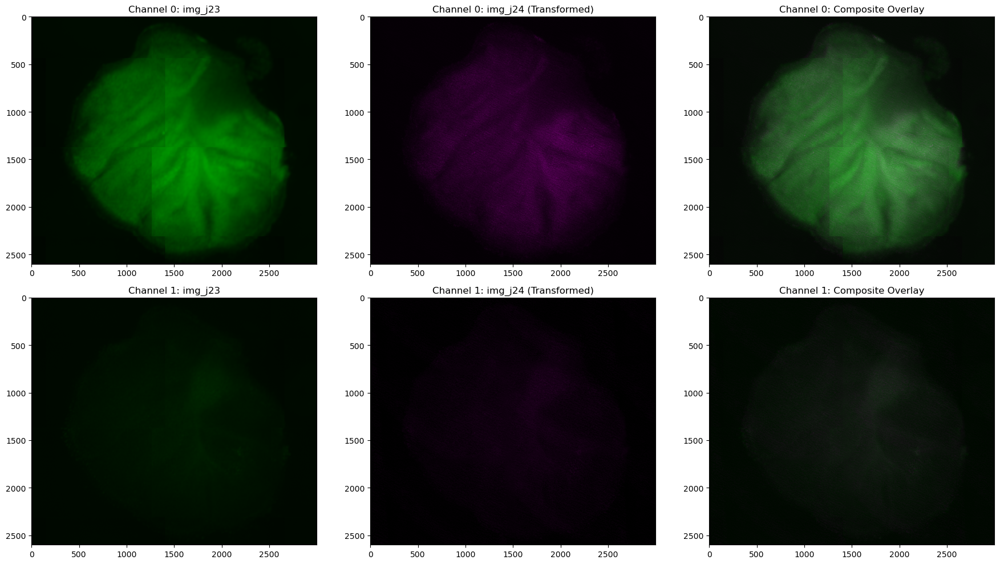

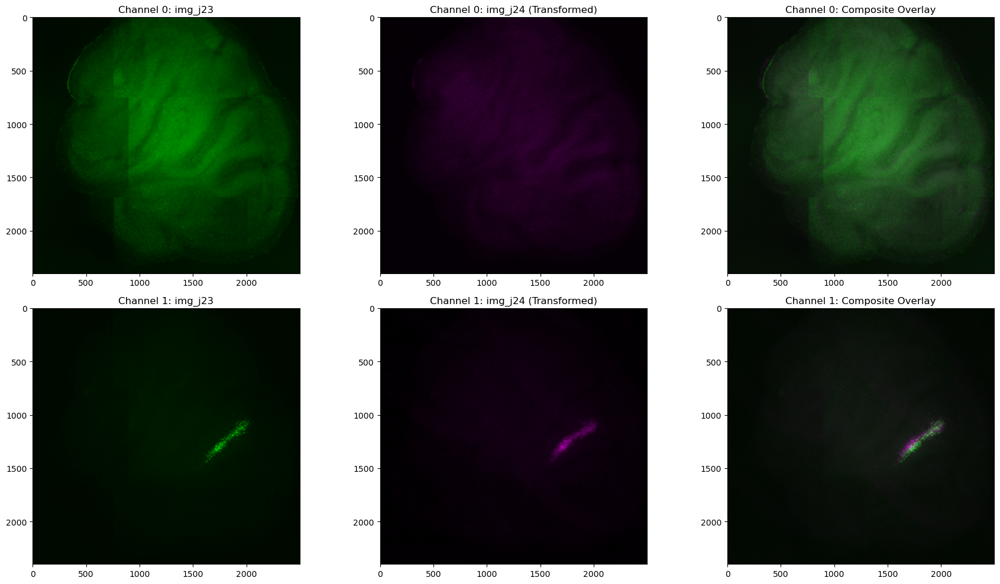

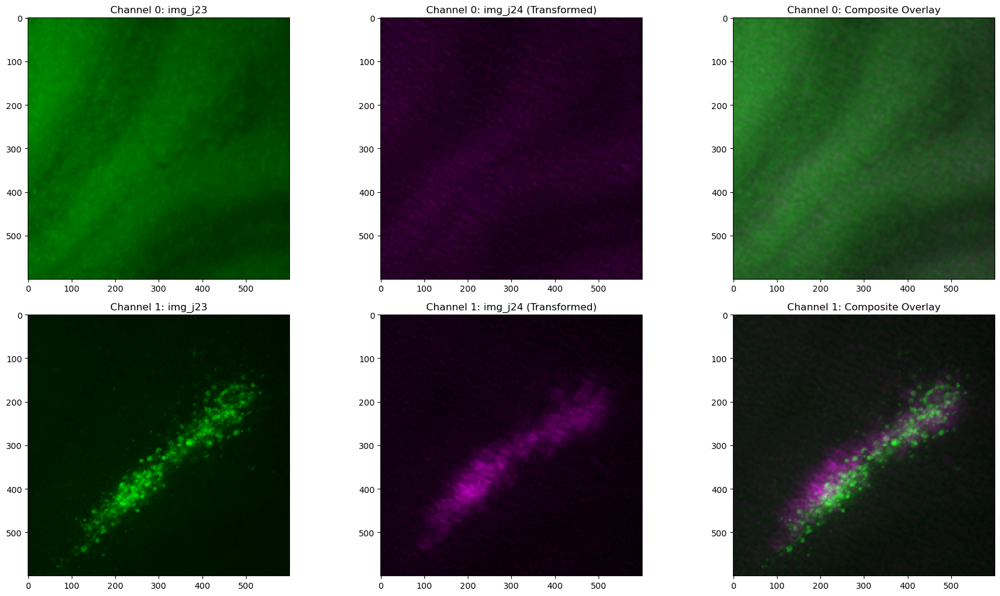

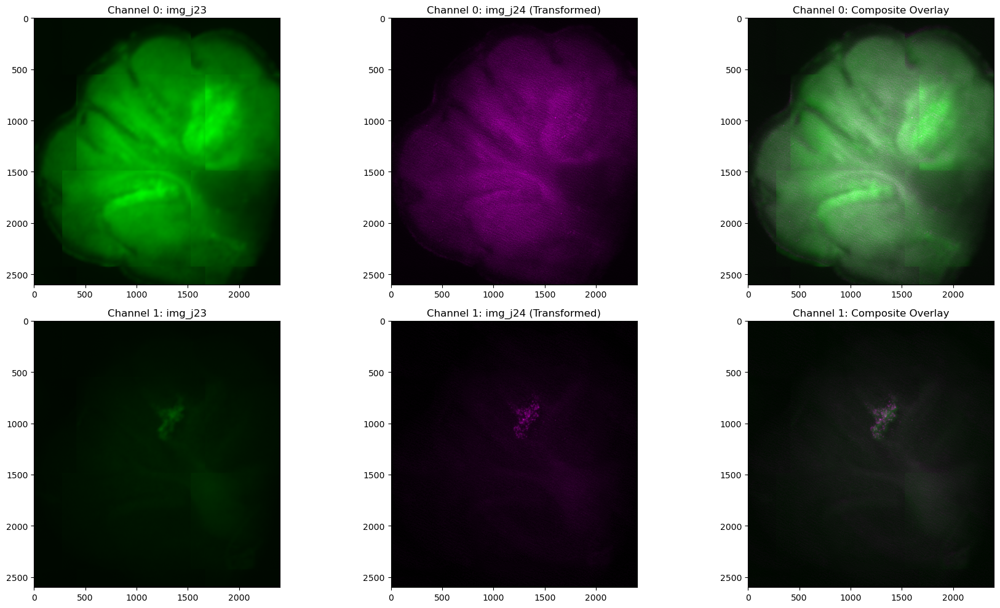

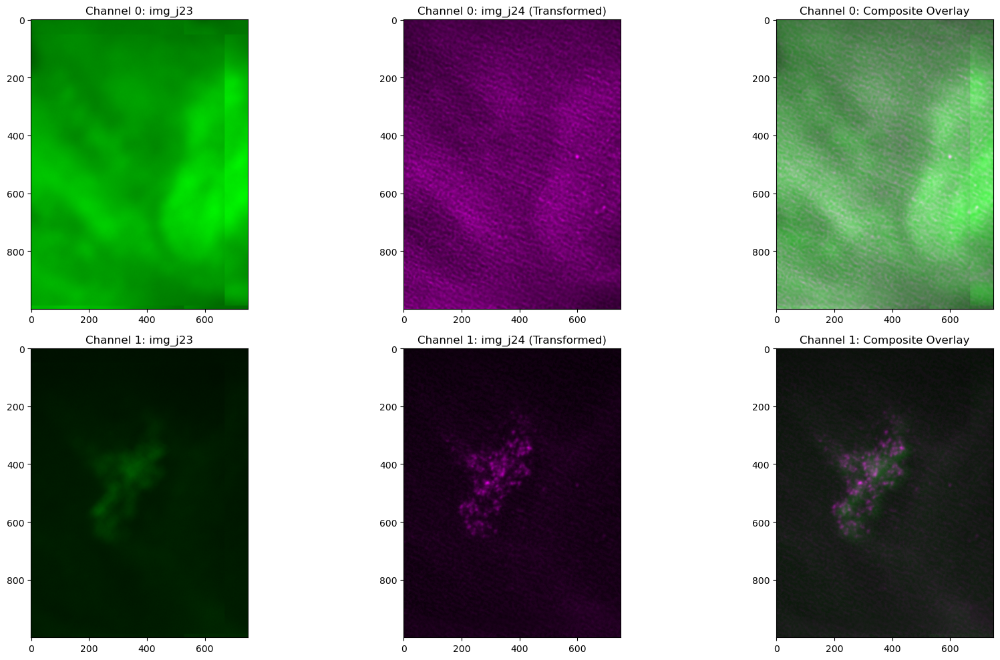

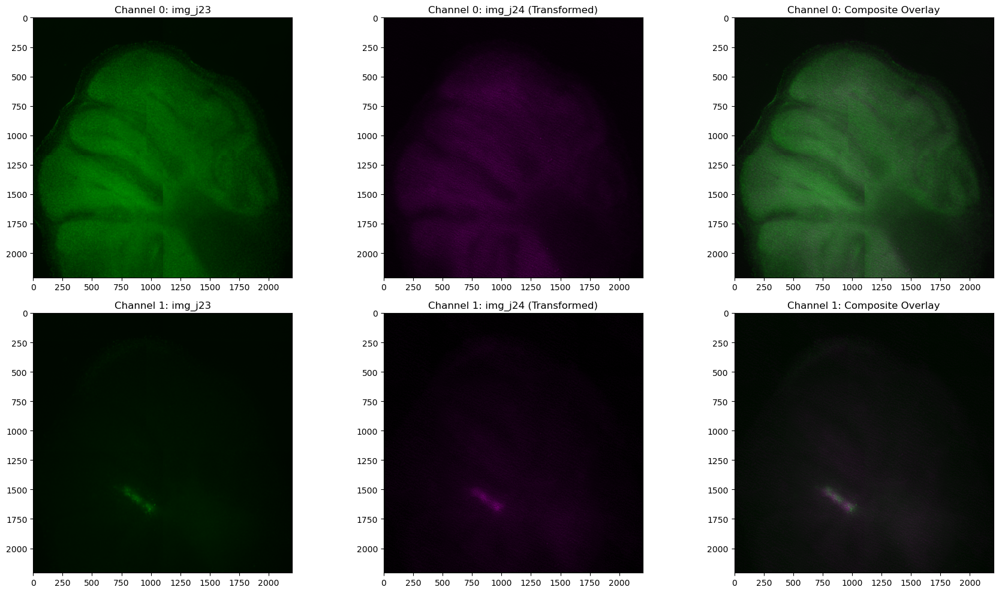

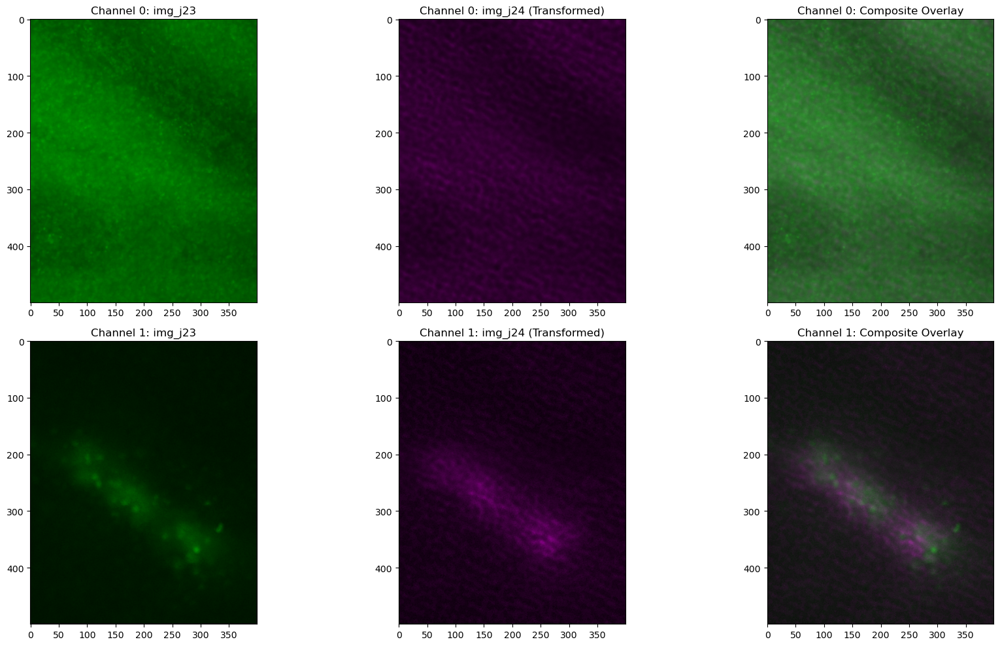

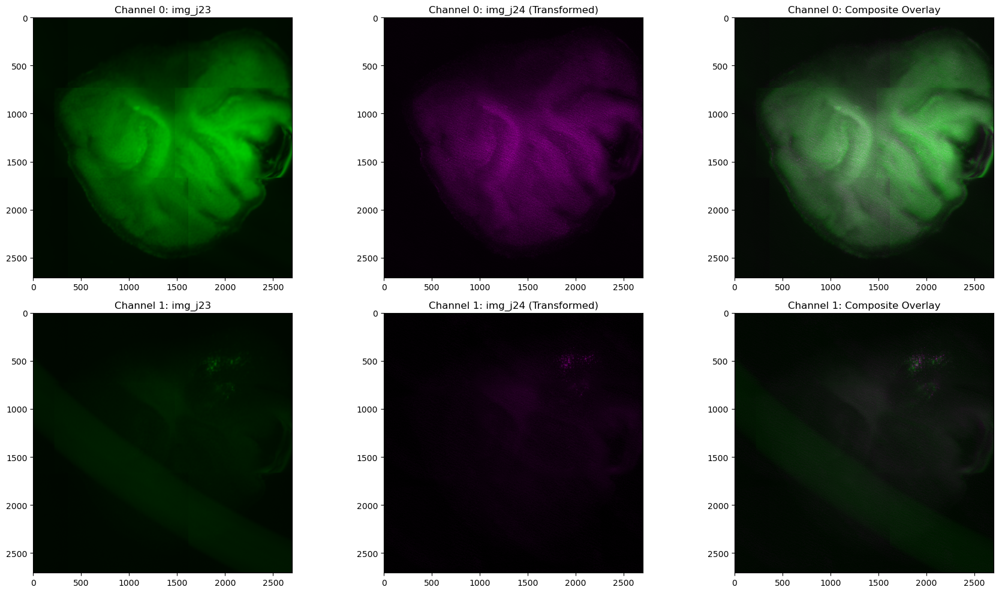

In [179]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
from skimage.transform import rotate
from scipy.ndimage import shift as nd_shift

def plot_registration_results(img1_all, img2_all, angle, translation_shift, crop=None):
    """
    Applies transformation and plots channel-wise comparisons.
    crop: (y_start, y_end, x_start, x_end)
    """
    # 1. Apply transform to both channels of img2
    # Assuming shape (C, Y, X)
    img2_final = np.zeros_like(img2_all, dtype=float)
    for c in range(img2_all.shape[0]):
        # Rotate then Shift
        transformed = nd_shift(rotate(img2_all[c], angle), translation_shift)
        # Rescale for visualization
        img2_final[c] = rescale_intensity(transformed, out_range=(0, 1))
    img2_final = img2_final[:,:13208,:15173]
    # 2. Prepare img1 for visualization
    img1_norm = np.zeros_like(img1_all, dtype=float)
    for c in range(img1_all.shape[0]):
        img1_norm[c] = rescale_intensity(img1_all[c].astype(float), out_range=(0, 1))

    # 3. Handle Cropping
    if crop:
        y0, y1, x0, x1 = crop
        img1_p = img1_norm[:, y0:y1, x0:x1]
        img2_p = img2_final[:, y0:y1, x0:x1]
    else:
        img1_p = img1_norm
        img2_p = img2_final

    # 4. Plotting
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    for c in range(2): # For each channel
        # img1
        composite = np.stack([np.zeros_like(img2_p[c]), img1_p[c], np.zeros_like(img2_p[c])], axis=2)
        axes[c, 0].imshow(composite,vmin=0,vmax=composite.max())
        axes[c, 0].set_title(f"Channel {c}: img_j23")
        
        # img2_final
        composite = np.stack([img2_p[c], np.zeros_like(img2_p[c]), img2_p[c]], axis=2)
        axes[c, 1].imshow(composite,vmin=0,vmax=composite.max())
        axes[c, 1].set_title(f"Channel {c}: img_j24 (Transformed)")
        
        # Composite (img1 in Green/Blue, img2 in Red/Magenta for overlap visibility)
        # Using a simple RGB stack for composite: [img2, img1, img1] -> img2 is Red, img1 is Cyan
        composite = np.stack([img2_p[c], img1_p[c], img2_p[c]], axis=2)
        axes[c, 2].imshow(composite,vmin=0,vmax=composite.max())
        axes[c, 2].set_title(f"Channel {c}: Composite Overlay")

    plt.tight_layout()
    plt.show()

# Detect parameters if you haven't yet (using the snippet from previous turn)
angle = 3.5 # 3 
shift = (-800, 400)

# Initial Full-Size Plot
plot_registration_results(img_j23, img_j24, angle=angle, translation_shift=shift)

# To test a specific crop:
crops = [(500, 3100, 5000, 8000),(5800,8200,3000,5500),(6700,7300,4500,5100),(6000,8600,11000,13400),(6500,7500,12000,12750),(11000,13210,5300,7500),(12300,12800,6000,6400),(10500,13210,9800,12500)]
for crop in crops:
    plot_registration_results(img_j23, img_j24, angle=angle, translation_shift=shift, crop=crop)

In [6]:
import xml.etree.ElementTree as ET

root = ET.parse(r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.tiff_files\Fibres_b0s0z0c0x0-1392y0-1040m0.tiff_metadata.xml").getroot()


[1,
 5,
 9,
 13,
 17,
 21,
 25,
 29,
 33,
 37,
 41,
 45,
 49,
 53,
 57,
 61,
 65,
 69,
 73,
 77,
 81,
 85,
 89,
 93,
 97,
 101,
 105,
 109,
 113,
 117,
 121,
 125,
 129,
 133,
 137,
 141,
 145,
 149,
 153,
 157,
 161,
 165,
 169,
 173,
 177,
 181,
 185,
 189,
 193,
 197,
 201,
 205,
 209]

In [16]:
for f in root[0]:
    print(f)

<Element 'AcquisitionTime' at 0x0000019E6CD06390>
<Element 'DetectorState' at 0x0000019E6CD061B0>
<Element 'StageXPosition' at 0x0000019E6CD06250>
<Element 'StageYPosition' at 0x0000019E6CD062F0>
<Element 'FocusPosition' at 0x0000019E6CCE8040>
<Element 'RoiCenterOffsetX' at 0x0000019E6CCE8090>
<Element 'RoiCenterOffsetY' at 0x0000019E6CCE80E0>


In [3]:
import re
import os
list_tiff = os.listdir(r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.tiff_files")
def extract_scene_id(filename):
    match = re.search(r"s(\d+)", filename)
    return match.group(1) if match else "0"
res = dict()
for f in list_tiff:
    s_id = extract_scene_id(f)
    print(s_id)
    res[f] = s_id

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
10
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
11
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
12
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
13
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
14
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
16
1

In [13]:
from tqdm import tqdm
import numpy as np
from skimage.io import imread

glob_min = np.inf
glob_max = 0

for f in tqdm(list_tiff):
    if f.endswith(".tiff"):
        img = imread(os.path.join(r"C:\Users\Emman\Desktop\work\These\Data\Camille\130426\Experiment-2732.tiff_files",f))
        glob_min = min(glob_min,img.min())
        glob_max = max(glob_max,img.max())
glob_min,glob_max

  0%|          | 0/2340 [00:00<?, ?it/s]

100%|██████████| 2340/2340 [00:58<00:00, 40.27it/s]


(np.uint8(0), np.uint8(255))

In [1]:
3+3

6

In [93]:
from bioio import BioImage
img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.czi",reconstruct_mosaic=False, include_subblock_metadata=True,
    use_aicspylibczi=True)
    
subblocks = img.metadata.findall("./Subblocks/Subblock")
print(len(subblocks))

1215


In [148]:
from bioio import BioImage

img = BioImage(
    r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

print(img.dims)
print(img.scenes)

<Dimensions [M: 1, T: 1, C: 3, Z: 5, Y: 1040, X: 1392]>
('P1-A1', 'P2-A1', 'P3-A1', 'P4-A1', 'P1-A1', 'P2-A1', 'P3-A1', 'P5-A1', 'P6-A1', 'P4-A1', 'P5-A1', 'P6-A1', 'P7-A1', 'P8-A1', 'P9-A1', 'P1-A1', 'P2-A1', 'P3-A1', 'P4-A1', 'P5-A1', 'P6-A1', 'P7-A1', 'P8-A1', 'P9-A1', 'P1-A2', 'P2-A2', 'P3-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P1-A2', 'P2-A2', 'P3-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'P1-A2', 'P2-A2', 'P3-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'TR3-A3')


In [99]:
group_list = [-1*np.ones(10) for i in range(6)]
seen = [[] for i in range(6)]
for i,scene in enumerate(img.scenes):
    try:
        idx_scene = int(scene[1])
        for idx_group in range(6):
            if group_list[idx_group][idx_scene] == -1:
                group_list[idx_group][idx_scene] = i
                seen[idx_group].append(scene)
                break
    except ValueError:
        pass

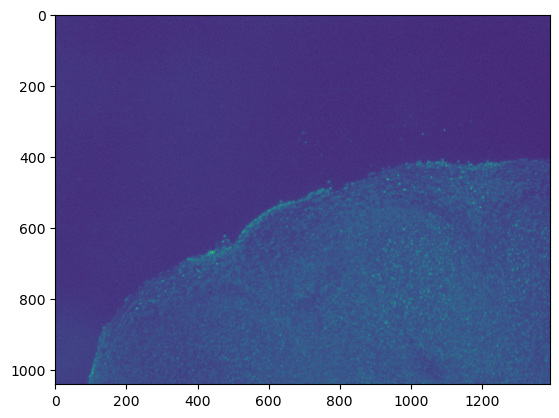

In [7]:
import matplotlib.pyplot as plt
img.set_scene(0)
plt.imshow(img.data[0,0,0,0])

In [10]:
from tqdm import tqdm
import os
import numpy as np
import tifffile
from bioio import BioImage
from skimage.metrics import structural_similarity as ssim, mean_squared_error as mse

# --- Parameters ---
Z_INDEX = 0   # choose which Z slice to use

# --- Load CZI ---
img = BioImage(
    r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

# --- Normalize ---
def normalize(im):
    im = im.astype(np.float32)
    im -= im.min()
    if im.max() > 0:
        im /= im.max()
    return im

# --- Load TIFFs (keep only channel 0) ---
tiff_dir = r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.tiff_files"

tiff_images = {}
for fname in os.listdir(tiff_dir):
    if fname.endswith(".tif") or fname.endswith(".tiff"):
        path = os.path.join(tiff_dir, fname)
        im = tifffile.imread(path)  # (X, Y, C)

        im_ch0 = im[..., 0]         # take first channel → (X, Y)
        tiff_images[fname] = normalize(im_ch0)

matching = dict()
# --- Matching ---
for i, scene in tqdm(enumerate(img.scenes)):
    img.set_scene(i)

    tile = img.data.squeeze()  # (C, Z, X, Y)

    # --- Select channel 0 and one Z ---
    slice_xy = tile[0, Z_INDEX, :, :]   # (X, Y)
    slice_norm = normalize(slice_xy)

    best_score = -1
    best_match = None

    for fname, tiff_im in tiff_images.items():

        if slice_norm.shape != tiff_im.shape:
            continue

        score = ssim(slice_norm, tiff_im, data_range=1.0)

        if score > best_score:
            best_score = score
            best_match = fname
    matching[i] = best_match
    print(f"Scene {i} -> {best_match} (SSIM={best_score:.4f})")

1it [03:34, 214.73s/it]

Scene 0 -> Fibres_b0s0z0c0x0-1392y0-1040m0.tiff (SSIM=0.6802)


2it [07:11, 216.14s/it]

Scene 1 -> Fibres_b0s1z0c0x1252-1392y0-1040m0.tiff (SSIM=0.7994)


3it [10:45, 215.08s/it]

Scene 2 -> Fibres_b0s2z0c0x0-1392y936-1040m0.tiff (SSIM=0.8240)


... (94 outputs left out)

51it [3:45:53, 229.83s/it]

Scene 50 -> Fibres_b0s50z0c0x38399-1392y5235-1040m0.tiff (SSIM=0.8060)


52it [3:45:59, 260.76s/it]

Scene 51 -> None (SSIM=-1.0000)


In [11]:
matching

{0: 'Fibres_b0s0z0c0x0-1392y0-1040m0.tiff',
 1: 'Fibres_b0s1z0c0x1252-1392y0-1040m0.tiff',
 2: 'Fibres_b0s2z0c0x0-1392y936-1040m0.tiff',
 3: 'Fibres_b0s3z0c0x1252-1392y936-1040m0.tiff',
 4: 'Fibres_b0s4z0c0x3418-1392y891-1040m0.tiff',
 5: 'Fibres_b0s5z0c0x4671-1392y891-1040m0.tiff',
 6: 'Fibres_b0s6z0c0x5924-1392y891-1040m0.tiff',
 7: 'Fibres_b0s7z0c0x0-1392y1872-1040m0.tiff',
 8: 'Fibres_b0s8z0c0x1252-1392y1872-1040m0.tiff',
 9: 'Fibres_b0s9z0c0x3418-1392y1827-1040m0.tiff',
 10: 'Fibres_b0s10z0c0x4671-1392y1827-1040m0.tiff',
 11: 'Fibres_b0s11z0c0x5924-1392y1827-1040m0.tiff',
 12: 'Fibres_b0s12z0c0x3418-1392y2763-1040m0.tiff',
 13: 'Fibres_b0s13z0c0x4671-1392y2763-1040m0.tiff',
 14: 'Fibres_b0s14z0c0x5924-1392y2763-1040m0.tiff',
 15: 'Fibres_b0s15z0c0x7962-1392y3186-1040m0.tiff',
 16: 'Fibres_b0s16z0c0x9215-1392y3186-1040m0.tiff',
 17: 'Fibres_b0s17z0c0x10467-1392y3186-1040m0.tiff',
 18: 'Fibres_b0s18z0c0x7962-1392y4122-1040m0.tiff',
 19: 'Fibres_b0s19z0c0x9215-1392y4122-1040m0.tiff',

In [ ]:
# import pickle
# # save dictionary to person_data.pkl file
# with open('matching_imgs.pkl', 'wb') as fp:
#     pickle.dump(matching, fp)
#     print('dictionary saved successfully to file')

In [25]:
import pickle
# save dictionary to person_data.pkl file
with open('matching_imgs.pkl', 'rb') as fp:
    matching = pickle.load(fp)
    print('dictionary saved successfully to file')

dictionary saved successfully to file


In [64]:
from bioio import BioImage

img = BioImage(
    r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

img.set_scene('TR3-A3')
img.data.shape
fig,ax = plt.subplots(3,10)
ax = ax.ravel()
for i in range(30):
    if i not in [2,29-12,22,9,29-19,29]:
        if i<10 or i>19:
            ax[i].imshow(img.data[i,0,0,0])
        else:
            ax[29-i].imshow(img.data[i,0,0,0])

<Dimensions [M: 1, T: 1, C: 3, Z: 5, Y: 1040, X: 1392]>
('P1-A1', 'P2-A1', 'P3-A1', 'P4-A1', 'P1-A1', 'P2-A1', 'P3-A1', 'P5-A1', 'P6-A1', 'P4-A1', 'P5-A1', 'P6-A1', 'P7-A1', 'P8-A1', 'P9-A1', 'P1-A1', 'P2-A1', 'P3-A1', 'P4-A1', 'P5-A1', 'P6-A1', 'P7-A1', 'P8-A1', 'P9-A1', 'P1-A2', 'P2-A2', 'P3-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P1-A2', 'P2-A2', 'P3-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'P1-A2', 'P2-A2', 'P3-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P4-A2', 'P5-A2', 'P6-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'P7-A2', 'P8-A2', 'P9-A2', 'TR3-A3')


In [66]:
img.set_scene('TR3-A3')
img.data.shape
fig,ax = plt.subplots(3,10)
ax = ax.ravel()
for i in range(30):
    if i not in [2,29-12,22,9,29-19,29]:
        if i<10 or i>19:
            ax[i].imshow(img.data[i,0,0,0])
        else:
            ax[29-i].imshow(img.data[i,0,0,0])

(30, 1, 3, 5, 1040, 1392)

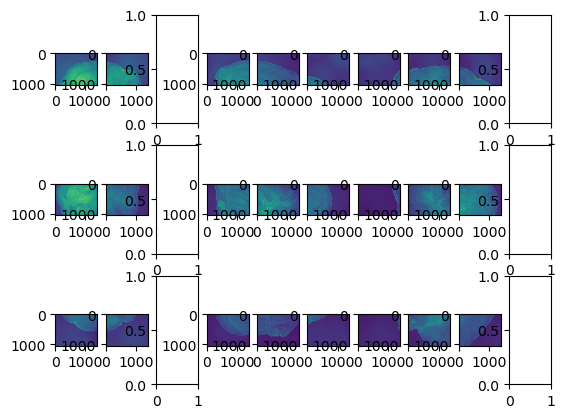

In [73]:
fig,ax = plt.subplots(3,10)
ax = ax.ravel()
for i in range(30):
    if i not in [2,29-12,22,9,29-19,29]:
        if i<10 or i>19:
            ax[i].imshow(img.data[i,0,0,0])
        else:
            ax[29-i].imshow(img.data[i,0,0,0])

In [ ]:
import numpy as np

def make_blend_mask(h, w, overlap_h, overlap_w):
    y = np.ones(h)
    x = np.ones(w)

    if overlap_h > 0:
        ramp = np.linspace(0, 1, overlap_h)
        y[:overlap_h] = ramp
        y[-overlap_h:] = ramp[::-1]

    if overlap_w > 0:
        ramp = np.linspace(0, 1, overlap_w)
        x[:overlap_w] = ramp
        x[-overlap_w:] = ramp[::-1]

    return np.outer(y, x)


def stitch_grid_blend(tiles, n_rows, n_cols, overlap=0.1):
    tile_h, tile_w = tiles[0].shape

    overlap_h = int(overlap * tile_h)
    overlap_w = int(overlap * tile_w)

    step_h = tile_h - overlap_h
    step_w = tile_w - overlap_w

    out_h = step_h * (n_rows - 1) + tile_h
    out_w = step_w * (n_cols - 1) + tile_w

    stitched = np.zeros((out_h, out_w), dtype=float)
    weight = np.zeros((out_h, out_w), dtype=float)

    mask = make_blend_mask(tile_h, tile_w, overlap_h, overlap_w)

    idx = 0
    for r in range(n_rows):
        for c in range(n_cols):
            y = r * step_h
            x = c * step_w

            tile = tiles[idx].astype(float)

            stitched[y:y+tile_h, x:x+tile_w] += tile * mask
            weight[y:y+tile_h, x:x+tile_w] += mask

            idx += 1

    return stitched / np.maximum(weight, 1e-8)
# tiles_scene1_idx = [0,1,19,18,20,21]
# tiles_scene2_idx = [3,4,5,29-13,29-14,29-15,23,24,25]
# tiles_scene3_idx = [6,7,8,29-16,29-17,29-18,26,27,28]

# tiles_scene1 = []
# tiles_scene2 = []
# tiles_scene3 = []
# for i,tiles_idx in enumerate([tiles_scene1_idx,tiles_scene2_idx,tiles_scene3_idx]):
#     for idx in tiles_idx:
#         if i==0:
#             tiles_scene1.append(img.data[idx,0,0,0])
#         elif i==1:
#             tiles_scene2.append(img.data[idx,0,0,0])
#         elif i==2:
#             tiles_scene3.append(img.data[idx,0,0,0])

# scene1 = stitch_grid_blend(tiles_scene1, 3, 2, overlap=0.1)
# scene2 = stitch_grid_blend(tiles_scene2, 3, 3, overlap=0.1)
# scene3 = stitch_grid_blend(tiles_scene3, 3, 3, overlap=0.1)

In [ ]:
def stitch_grid_blend_multichannel(tiles, n_rows, n_cols, overlap=0.1):
    # tiles: list of (C, H, W)
    C, tile_h, tile_w = tiles[0].shape

    overlap_h = int(overlap * tile_h)
    overlap_w = int(overlap * tile_w)

    step_h = tile_h - overlap_h
    step_w = tile_w - overlap_w

    out_h = step_h * (n_rows - 1) + tile_h
    out_w = step_w * (n_cols - 1) + tile_w

    stitched = np.zeros((C, out_h, out_w), dtype=np.float64)
    weight = np.zeros((out_h, out_w), dtype=np.float64)

    mask = make_blend_mask(tile_h, tile_w, overlap_h, overlap_w)

    idx = 0
    for r in range(n_rows):
        for c in range(n_cols):
            y = r * step_h
            x = c * step_w

            tile = tiles[idx].astype(np.float64)  # (C, H, W)

            for ch in range(C):
                stitched[ch, y:y+tile_h, x:x+tile_w] += tile[ch] * mask

            weight[y:y+tile_h, x:x+tile_w] += mask
            idx += 1

    return stitched / np.maximum(weight, 1e-8)


In [165]:
import numpy as np

def stitch_grid_max(tiles, n_rows, n_cols, overlap=0.1):
    # tiles: list of (C, H, W)
    C, tile_h, tile_w = tiles[0].shape

    overlap_h = int(overlap * tile_h)
    overlap_w = int(overlap * tile_w)

    step_h = tile_h - overlap_h
    step_w = tile_w - overlap_w

    out_h = step_h * (n_rows - 1) + tile_h
    out_w = step_w * (n_cols - 1) + tile_w

    stitched = np.zeros((C, out_h, out_w), dtype=tiles[0].dtype)

    idx = 0
    for r in range(n_rows):
        for c in range(n_cols):
            y = r * step_h
            x = c * step_w

            tile = tiles[idx]  # (C, H, W)

            for ch in range(C):
                stitched[ch, y:y+tile_h, x:x+tile_w] = np.maximum(
                    stitched[ch, y:y+tile_h, x:x+tile_w],
                    tile[ch]
                )

            idx += 1

    return stitched

In [166]:
tiles_scene1_idx = [0,1,19,18,20,21]
tiles_scene2_idx = [3,4,5,29-13,29-14,29-15,23,24,25]
tiles_scene3_idx = [6,7,8,29-16,29-17,29-18,26,27,28]
tiles_scene1 = []
tiles_scene2 = []
tiles_scene3 = []
img.set_scene('TR3-A3')
img_proj = img.data.max(axis=3) 
for i, tiles_idx in enumerate([tiles_scene1_idx, tiles_scene2_idx, tiles_scene3_idx]):
    for idx in tiles_idx:
        tile = img_proj[idx, 0]  # (C, H, W)

        if i == 0:
            tiles_scene1.append(tile)
        elif i == 1:
            tiles_scene2.append(tile)
        elif i == 2:
            tiles_scene3.append(tile)
scene1 = stitch_grid_max(tiles_scene1, 3, 2, overlap=0.1)
scene2 = stitch_grid_max(tiles_scene2, 3, 3, overlap=0.1)
scene3 = stitch_grid_max(tiles_scene3, 3, 3, overlap=0.1)

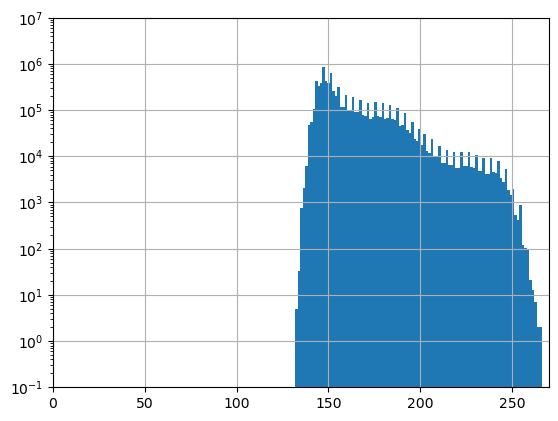

In [167]:
plt.hist(scene1[1].flatten(),bins=100)
plt.yscale('log')
plt.xlim([0,270])
plt.ylim([0.1,10**7])
plt.grid()

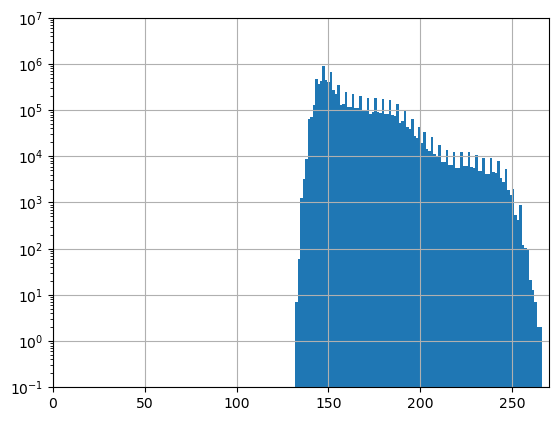

In [168]:
plt.hist(np.array(tiles_scene1)[:,1].flatten(),bins=100)
plt.yscale('log')
plt.xlim([0,270])
plt.ylim([0.1,10**7])
plt.grid()

In [125]:
from skimage.io import imsave
import os
folder = r"C:\Users\Emman\Desktop\work\These\Code\Stitcher\data\output\Fibres\090426"
for name,file in zip(['Tr1_Insert3','Tr2_Insert3','Tr3_Insert3'],[scene1,scene2,scene3]):
    imsave(os.path.join(folder,name+'.tiff'),file)
    

In [133]:
list_imgs = []
for scene in img.scenes[:40]:
    img.set_scene(scene)
    list_imgs.append(img.data)
list_imgs = np.array(list_imgs)

(array([1.983000e+03, 6.985000e+04, 6.883570e+05, 2.069829e+06,
        5.008110e+06, 6.574386e+06, 5.541885e+06, 5.693311e+06,
        4.955500e+06, 2.828882e+06, 1.639512e+06, 9.592570e+05,
        7.677210e+05, 9.064380e+05, 8.622010e+05, 7.577450e+05,
        8.849010e+05, 9.575960e+05, 8.359120e+05, 9.095280e+05,
        8.989250e+05, 7.857750e+05, 9.322510e+05, 9.781950e+05,
        9.075870e+05, 1.016880e+06, 9.854080e+05, 8.923840e+05,
        7.291200e+05, 7.087980e+05, 6.236210e+05, 5.095580e+05,
        5.179340e+05, 4.756820e+05, 3.935020e+05, 4.137850e+05,
        3.461500e+05, 2.599890e+05, 2.430760e+05, 2.143100e+05,
        1.604280e+05, 1.585570e+05, 1.424490e+05, 1.159310e+05,
        1.218380e+05, 1.106840e+05, 9.439800e+04, 9.645000e+04,
        9.595400e+04, 8.719800e+04, 1.054090e+05, 1.048680e+05,
        1.027000e+05, 8.119200e+04, 7.638300e+04, 6.060100e+04,
        4.005200e+04, 3.611300e+04, 2.913700e+04, 2.310100e+04,
        2.326700e+04, 2.249500e+04, 1.78

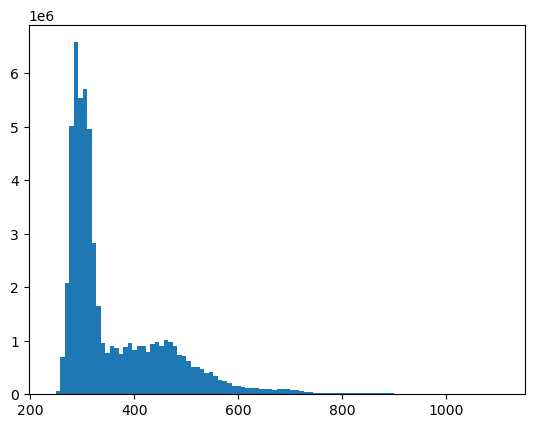

In [137]:
plt.hist(np.max(list_imgs[:,0,0,1],axis=1).flatten(),bins=100)

(array([2.0000e+00, 7.0000e+00, 2.6000e+01, 0.0000e+00, 9.6000e+01,
        2.8500e+02, 8.1200e+02, 0.0000e+00, 1.9890e+03, 4.5630e+03,
        0.0000e+00, 9.1700e+03, 1.7499e+04, 2.8921e+04, 0.0000e+00,
        4.5560e+04, 6.4327e+04, 0.0000e+00, 8.2418e+04, 9.2586e+04,
        9.5459e+04, 0.0000e+00, 9.0629e+04, 7.7880e+04, 0.0000e+00,
        6.4734e+04, 5.1215e+04, 3.8848e+04, 0.0000e+00, 3.6336e+04,
        3.1281e+04, 2.7862e+04, 0.0000e+00, 2.6411e+04, 2.5013e+04,
        0.0000e+00, 2.4088e+04, 2.3671e+04, 2.3091e+04, 0.0000e+00,
        2.3476e+04, 2.1500e+04, 0.0000e+00, 2.0056e+04, 1.9652e+04,
        1.8021e+04, 0.0000e+00, 1.7810e+04, 1.7750e+04, 0.0000e+00,
        1.5934e+04, 1.8948e+04, 1.9902e+04, 0.0000e+00, 2.0739e+04,
        2.0931e+04, 2.0776e+04, 0.0000e+00, 2.0822e+04, 2.0347e+04,
        0.0000e+00, 1.9444e+04, 1.9213e+04, 1.8744e+04, 0.0000e+00,
        1.7420e+04, 1.6565e+04, 0.0000e+00, 1.4673e+04, 1.2440e+04,
        1.0738e+04, 0.0000e+00, 7.8710e+03, 6.97

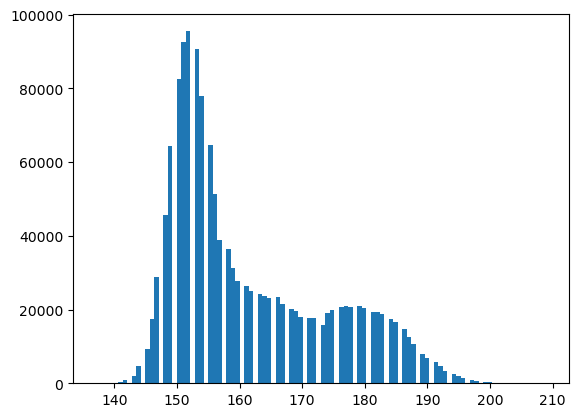

In [130]:
plt.hist(np.max(img.data[0,0,1],axis=0).flatten(),bins=100)

In [38]:
from skimage.io import imread,imsave
import os
# fig,ax = plt.subplots(len(matching.keys()),2,figsize=(8,len(matching.keys())))
folder = r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres.tiff_files"
folder2 = r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2"
os.makedirs(folder2,exist_ok=True)
for i,key in enumerate(matching.keys()):
    img.set_scene(key)
    for c in range(3):
        if matching[key] is not None:
            temp = np.max(img.data[0,0,c],axis=0)
            imsave(os.path.join(folder2,matching[key].replace('c0',f'c{c}')),temp)
            # ax[i,0].imshow(temp,vmin=temp.min(),vmax=temp.max(),cmap='gray')
            # temp = imread(os.path.join(folder,matching[key]))
            # ax[i,1].imshow(temp,vmin=temp.min(),vmax=temp.max(),cmap='gray')
            # ax[i,0].set_title(matching[key])
 

c:\Users\Emman\miniforge3\envs\bioio\Lib\site-packages\skimage\_shared\utils.py:386: UserWarning: C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2\Fibres_b0s0z0c0x0-1392y0-1040m0.tiff is a low contrast image
  return func(*args, **kwargs)
c:\Users\Emman\miniforge3\envs\bioio\Lib\site-packages\skimage\_shared\utils.py:386: UserWarning: C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2\Fibres_b0s0z0c1x0-1392y0-1040m0.tiff is a low contrast image
  return func(*args, **kwargs)
c:\Users\Emman\miniforge3\envs\bioio\Lib\site-packages\skimage\_shared\utils.py:386: UserWarning: C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2\Fibres_b0s0z0c2x0-1392y0-1040m0.tiff is a low contrast image
  return func(*args, **kwargs)
c:\Users\Emman\miniforge3\envs\bioio\Lib\site-packages\skimage\_shared\utils.py:386: UserWarning: C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2\Fibres_b0s1z0c0x1252-1392y0-1040m0.tiff is a low contrast image
  return func(*args,

In [ ]:
# import pickle
# # save dictionary to person_data.pkl file
# with open('matching_imgs.pkl', 'wb') as fp:
#     pickle.dump(matching, fp)
#     print('dictionary saved successfully to file')

dictionary saved successfully to file


In [52]:
# import numpy as np
# import tifffile
# import os


# def make_weight_map(Y, X, overlap_y, overlap_x):
#     """
#     Create a feathering weight map
#     """
#     wy = np.ones(Y)
#     wx = np.ones(X)

#     oy = int(Y * overlap_y)
#     ox = int(X * overlap_x)

#     # vertical ramps
#     if oy > 0:
#         ramp = np.linspace(0, 1, oy)
#         wy[:oy] = ramp
#         wy[-oy:] = ramp[::-1]

#     # horizontal ramps
#     if ox > 0:
#         ramp = np.linspace(0, 1, ox)
#         wx[:ox] = ramp
#         wx[-ox:] = ramp[::-1]

#     weight = np.outer(wy, wx)
#     return weight


# def stitch_tiles_snake(
#     tiles,
#     n_rows,
#     n_cols,
#     overlap_x=0.1,
#     overlap_y=0.1,
#     mode="blend"  # "max" or "blend"
# ):
#     """
#     tiles: (tile, Y, X)
#     """
#     n_tiles, Y, X = tiles.shape

#     step_x = int(X * (1 - overlap_x))
#     step_y = int(Y * (1 - overlap_y))

#     stitched_Y = step_y * (n_rows - 1) + Y
#     stitched_X = step_x * (n_cols - 1) + X

#     if mode == "max":
#         canvas = np.zeros((stitched_Y, stitched_X), dtype=tiles.dtype)

#     elif mode == "blend":
#         canvas = np.zeros((stitched_Y, stitched_X), dtype=np.float32)
#         norm = np.zeros((stitched_Y, stitched_X), dtype=np.float32)
#         weight_map = make_weight_map(Y, X, overlap_y, overlap_x)

#     else:
#         raise ValueError("mode must be 'max' or 'blend'")

#     for t in range(n_tiles):
#         row = t // n_cols

#         # snake ordering
#         if row % 2 == 1:
#             col = n_cols - 1 - (t % n_cols)
#         else:
#             col = t % n_cols

#         y0 = row * step_y
#         x0 = col * step_x

#         tile = tiles[t]

#         if mode == "max":
#             canvas[y0:y0+Y, x0:x0+X] = np.maximum(
#                 canvas[y0:y0+Y, x0:x0+X],
#                 tile
#             )

#         elif mode == "blend":
#             w = weight_map

#             canvas[y0:y0+Y, x0:x0+X] += tile * w
#             norm[y0:y0+Y, x0:x0+X] += w

#     if mode == "blend":
#         canvas = canvas / np.maximum(norm, 1e-8)
#         canvas = canvas.astype(tiles.dtype)

#     return canvas

In [83]:
# import numpy as np
# import tifffile
# import os

# output_dir = "stitched_output"
# os.makedirs(output_dir, exist_ok=True)

# n_scenes, n_tiles, n_time, n_channels, n_z, Y, X = all_data.shape

# n_rows, n_cols = 3, 3
# mode = "blend"  # or "max"
# all_stitched = []
# for s in range(n_scenes):

#     stitched_channels = []

#     for c in range(n_channels):

#         tiles = all_data[s, :, 0, c, :, :, :]  # remove time

#         # Z max projection
#         tiles_proj = tiles.max(axis=1)  # (tile, Y, X)

#         stitched = stitch_tiles_snake(
#             tiles_proj,
#             n_rows=n_rows,
#             n_cols=n_cols,
#             overlap_x=0.10,
#             overlap_y=0.10,
#             mode=mode
#         )

#         stitched_channels.append(stitched)

#     # stack channels → (C, Y, X)
#     stitched_channels = np.stack(stitched_channels, axis=0) 
#     all_stitched.append(stitched_channels)
#     # save one TIFF per scene
#     tifffile.imwrite(
#         os.path.join(output_dir, f"scene_{s:02d}.tif"),
#         stitched_channels
#     )

In [51]:
# import numpy as np
# import tifffile
# import os


# def get_grid(n_tiles):
#     if n_tiles == 9:
#         return 3, 3
#     if n_tiles == 6:
#         return 3, 2
#     raise ValueError(f"Unsupported tile count: {n_tiles}")


# output_dir = "stitched_output"
# os.makedirs(output_dir, exist_ok=True)

# n_scenes, _, n_time, n_channels, n_z, Y, X = all_data.shape

# mode = "blend"  # or "max"

# for s in range(n_scenes):

#     # detect actual number of tiles for this scene
#     # (assuming unused tiles are not present — if padded, tell me)
#     tiles_scene = all_data[s]

#     # detect non-empty tiles
#     valid = [i for i in range(tiles_scene.shape[0]) if tiles_scene[i].sum() > 0]
#     tiles_scene = tiles_scene[valid]
#     n_tiles = len(valid)

#     n_rows, n_cols = get_grid(n_tiles)

#     print(f"Scene {s}: {n_tiles} tiles → grid {n_rows}x{n_cols}")

#     stitched_channels = []

#     for c in range(n_channels):

#         tiles = tiles_scene[:, 0, c, :, :, :]  # remove time

#         # Z max projection
#         tiles_proj = tiles.max(axis=1)  # (tile, Y, X)

#         stitched = stitch_tiles_snake(
#             tiles_proj,
#             n_rows=n_rows,
#             n_cols=n_cols,
#             overlap_x=0.10,
#             overlap_y=0.10,
#             mode=mode
#         )

#         stitched_channels.append(stitched)

#     stitched_channels = np.stack(stitched_channels, axis=0).astype(np.int16)
#     tifffile.imwrite(
#         os.path.join(output_dir, f"scene_{s:02d}.tif"),
#         stitched_channels,
#         imagej=True
#     )

In [100]:

group_list = [group[group!=-1] for group in group_list]
group_list = [[int(x) for x in group] for group in group_list]
group_list

[[0, 1, 2, 3, 7, 8, 12, 13, 14],
 [4, 5, 6, 9, 10, 11, 21, 22, 23],
 [15, 16, 17, 18, 19, 20, 33, 34, 35],
 [24, 25, 26, 27, 28, 29, 45, 46, 47],
 [30, 31, 32, 39, 40, 41, 48, 49, 50],
 [36, 37, 38, 42, 43, 44]]

In [120]:
def stitch_from_group(group_tiles, tiles, overlap_x=0.1, overlap_y=0.1, mode="blend"):
    Y, X = tiles.shape[1], tiles.shape[2]

    step_y = int(Y * (1 - overlap_y))
    step_x = int(X * (1 - overlap_x))

    n_rows = len(group_tiles)
    max_cols = max(len(r) for r in group_tiles)

    out_Y = step_y * (n_rows - 1) + Y
    out_X = step_x * (max_cols - 1) + X

    if mode == "max":
        canvas = np.zeros((out_Y, out_X), dtype=tiles.dtype)
    else:
        canvas = np.zeros((out_Y, out_X), dtype=np.float32)
        norm = np.zeros((out_Y, out_X), dtype=np.float32)

        wy = np.ones(Y)
        wx = np.ones(X)

        oy = int(Y * overlap_y)
        ox = int(X * overlap_x)

        if oy > 0:
            r = np.linspace(0, 1, oy)
            wy[:oy] = r
            wy[-oy:] = r[::-1]

        if ox > 0:
            r = np.linspace(0, 1, ox)
            wx[:ox] = r
            wx[-ox:] = r[::-1]

        weight = np.outer(wy, wx)

    for r, row in enumerate(group_tiles):
        for c, tile_idx in enumerate(row):

            tile = tiles[tile_idx]
            y0 = r * step_y
            x0 = c * step_x

            if mode == "max":
                canvas[y0:y0+Y, x0:x0+X] = np.maximum(
                    canvas[y0:y0+Y, x0:x0+X],
                    tile
                )
            else:
                canvas[y0:y0+Y, x0:x0+X] += tile * weight
                norm[y0:y0+Y, x0:x0+X] += weight

    if mode == "blend":
        canvas = canvas / np.maximum(norm, 1e-8)
        canvas = canvas.astype(tiles.dtype)

    return canvas

In [117]:
import numpy as np
import tifffile
import os


def extract_tiles_from_group(img, group, n_channels):
    """
    Returns:
        tiles: (N, C, Z, Y, X)
    """

    tiles = []

    for i in group:
        img.set_scene(i)
        data = img.data  # (C, Z, Y, X)
        tiles.append(data)

    return np.stack(tiles, axis=0)

In [118]:
def getGroupLayout(group):
    if len(group) ==4:
        return [[0,1],[3,2]]
    elif len(group)==9:
        return [[0,1,2],[5,4,3],[6,7,8]]
    return -1

In [135]:
from tqdm import tqdm
output_dir = "stitched_output"
os.makedirs(output_dir, exist_ok=True)

mode = "blend"

for g_idx, group in tqdm(enumerate(group_list)):

    # 1. extract all tiles for this group
    tile_data = extract_tiles_from_group(img, group, n_channels=3)
    tile_data = tile_data[:,0,0]
    # shape: (N_tiles, C, Z, Y, X)

    n_tiles = tile_data.shape[0]

    stitched_channels = []

    for c in range(tile_data.shape[1]):
        tiles = tile_data[:, c]          # (tile, Z, Y, X)
        tiles = tiles.max(axis=1)        # Z projection → (tile, Y, X)
        try:
            stitched = stitch_from_group(
                np.array([[0, 1, 2],
                    [5, 4, 3],
                    [6, 7, 8]]),
                tiles,
                overlap_x=0.10,
                overlap_y=0.10,
                mode=mode
            )
        except IndexError:
            stitched = stitch_from_group(
                np.array([[0, 1],
                    [3, 2],
                    [4, 5]]),
                tiles,
                overlap_x=0.10,
                overlap_y=0.10,
                mode=mode
            )

        stitched_channels.append(stitched)

    stitched_channels = np.stack(stitched_channels, axis=0)
    break
    # tifffile.imwrite(
    #     os.path.join(output_dir, f"group_{g_idx:02d}.tif"),
    #     stitched_channels,
    #     imagej=True
    # )

0it [00:05, ?it/s]


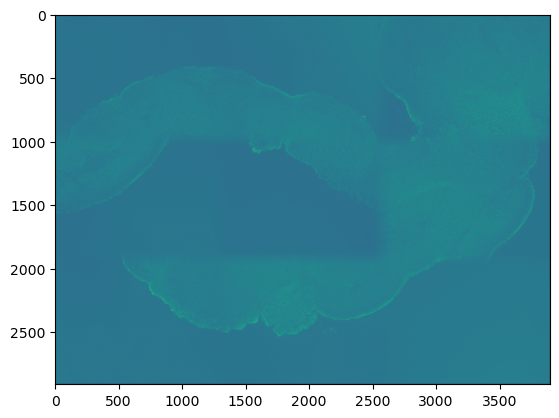

In [136]:
plt.imshow(stitched_channels[0])

In [ ]:
plt.imshow(stitched_channels[0])

array([[0, 1],
       [3, 2],
       [4, 5]])

In [56]:
import re
import numpy as np
import tifffile as tiff
from pathlib import Path


def parse_filename(fname):
    pattern = r"c(\d+)x(\d+)-(\d+)y(\d+)-(\d+)"
    m = re.search(pattern, fname)
    if m is None:
        raise ValueError(f"Cannot parse {fname}")
    
    x = int(m.group(2))
    w = int(m.group(3))
    y = int(m.group(4))
    h = int(m.group(5))
    c = int(m.group(1))
    
    return x, y, w, h, c


def load_tiles(input_dir):
    """
    Group files into multi-channel tiles by (x, y)
    """
    tiles = {}
    
    for f in Path(input_dir).glob("*.tiff"):
        if "metadata" in f.name:
            continue
        
        x, y, w, h, c = parse_filename(f.name)
        key = (x, y)
        
        if key not in tiles:
            tiles[key] = {
                "x": x,
                "y": y,
                "w": w,
                "h": h,
                "channels": {}
            }
        
        tiles[key]["channels"][c] = f
    
    # convert to list
    return list(tiles.values())


def build_multichannel_image(tile):
    """
    Load channels and stack into (C, Y, X)
    """
    channels = tile["channels"]
    max_c = max(channels.keys())
    
    imgs = []
    for c in range(max_c + 1):
        if c not in channels:
            raise ValueError(f"Missing channel {c} at tile {tile['x'], tile['y']}")
        
        img = tiff.imread(channels[c])
        imgs.append(img)
    
    return np.stack(imgs, axis=0)  # (C, Y, X)


def cluster_tiles(tiles):
    coords = np.array([[t["x"], t["y"]] for t in tiles])
    
    dx = np.median([t["w"] for t in tiles])
    dy = np.median([t["h"] for t in tiles])
    threshold = max(dx, dy) * 0.99
    
    clusters = []
    unassigned = set(range(len(tiles)))
    
    while unassigned:
        seed = unassigned.pop()
        cluster = {seed}
        stack = [seed]
        
        while stack:
            i = stack.pop()
            xi, yi = coords[i]
            
            neighbors = []
            for j in list(unassigned):
                xj, yj = coords[j]
                dist = np.sqrt((xi - xj)**2 + (yi - yj)**2)
                
                if dist < threshold:
                    neighbors.append(j)
            
            for j in neighbors:
                unassigned.remove(j)
                cluster.add(j)
                stack.append(j)
        
        clusters.append([tiles[i] for i in cluster])
    
    return clusters


import numpy as np


def compute_overlap(w, h, overlap=0.1):
    ox = int(round(w * overlap))
    oy = int(round(h * overlap))
    return ox, oy


def stitch_cluster(cluster, mode="blend", overlap=0.1):
    """
    mode: "max" or "blend"
    output: (C, Y, X)
    """
    xs = [t["x"] for t in cluster]
    ys = [t["y"] for t in cluster]
    
    min_x, min_y = min(xs), min(ys)
    
    tiles = []
    
    for t in cluster:
        img = build_multichannel_image(t)  # (C, Y, X)
        x = t["x"] - min_x
        y = t["y"] - min_y
        tiles.append((x, y, img))
    
    C, H, W = tiles[0][2].shape
    
    # overlap size
    ox, oy = compute_overlap(W, H, overlap)
    
    max_x = max(x + W for x, y, _ in tiles)
    max_y = max(y + H for x, y, _ in tiles)
    
    if mode == "max":
        canvas = np.zeros((C, max_y, max_x), dtype=tiles[0][2].dtype)
        
        for x, y, img in tiles:
            region = canvas[:, y:y+H, x:x+W]
            np.maximum(region, img, out=region)
        
        return canvas
    
    elif mode == "blend":
        # float accumulation
        acc = np.zeros((C, max_y, max_x), dtype=np.float32)
        weight = np.zeros((max_y, max_x), dtype=np.float32)
        
        # build feathering mask once
        wy = np.ones(H, dtype=np.float32)
        wx = np.ones(W, dtype=np.float32)
        
        # linear ramps
        if oy > 0:
            ramp = np.linspace(0, 1, oy)
            wy[:oy] = ramp
            wy[-oy:] = ramp[::-1]
        
        if ox > 0:
            ramp = np.linspace(0, 1, ox)
            wx[:ox] = ramp
            wx[-ox:] = ramp[::-1]
        
        mask = np.outer(wy, wx)  # (H, W)
        
        for x, y, img in tiles:
            m = mask
            
            acc[:, y:y+H, x:x+W] += img * m
            weight[y:y+H, x:x+W] += m
        
        # avoid division by zero
        weight = np.maximum(weight, 1e-6)
        
        result = acc / weight
        
        # cast back safely
        dtype = tiles[0][2].dtype
        
        if np.issubdtype(dtype, np.integer):
            info = np.iinfo(dtype)
            result = np.clip(result, info.min, info.max)
        
        return result.astype(dtype)
    
    else:
        raise ValueError("mode must be 'max' or 'blend'")

def stitch_all(input_dir, output_dir):
    input_dir = Path(input_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    
    tiles = load_tiles(input_dir)
    clusters = cluster_tiles(tiles)
    
    print(f"Found {len(clusters)} spatial scenes")
    
    for i, cluster in enumerate(clusters):
        print(f"Scene {i}: {len(cluster)} tiles")
        
        stitched = stitch_cluster(cluster)
        
        out_path = output_dir / f"scene_{i:02d}.tiff"
        
        # Save as ImageJ-compatible hyperstack
        tiff.imwrite(
            out_path,
            stitched,
            imagej=True,
            metadata={"axes": "CYX"}
        )

In [57]:
stitch_all(r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres2", r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres_stitched")

Found 6 spatial scenes
Scene 0: 6 tiles
Scene 1: 9 tiles
Scene 2: 9 tiles
Scene 3: 9 tiles
Scene 4: 9 tiles
Scene 5: 9 tiles


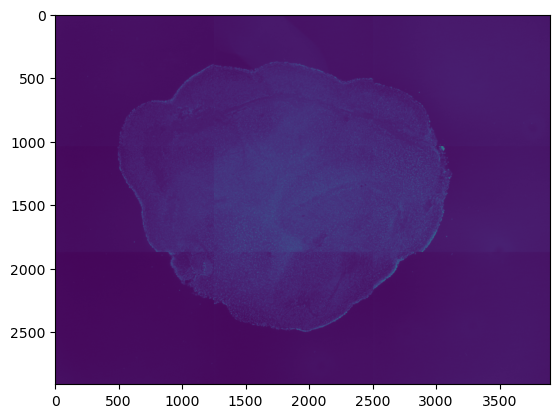

In [23]:
from skimage.io import imread
import matplotlib.pyplot as plt

plt.imshow(imread(r"C:\Users\Emman\Desktop\work\These\Data\Camille\090426\Fibres_stitched\stitched_05.tiff"))

In [22]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt

img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\041726\Experiment-2735.czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True)
img = img.data[:,0,0,0]
np.sum(img)/1e9

np.float64(20.778746004)

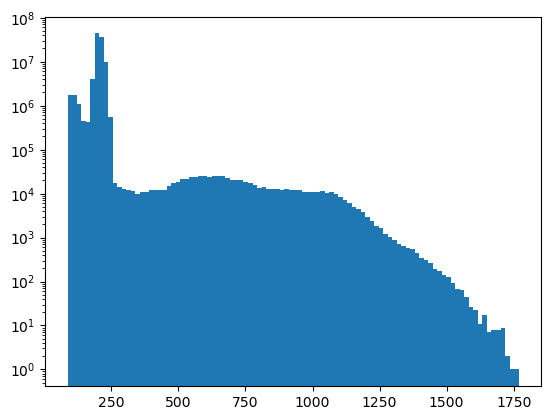

In [23]:
plt.hist(img.flatten(),bins=100)
plt.yscale('log')

In [24]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt

img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\04152026\Experiment-2735.czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)
img = img.data[:,0,0,0]
np.sum(img)/1e9

np.float64(17.759733375)

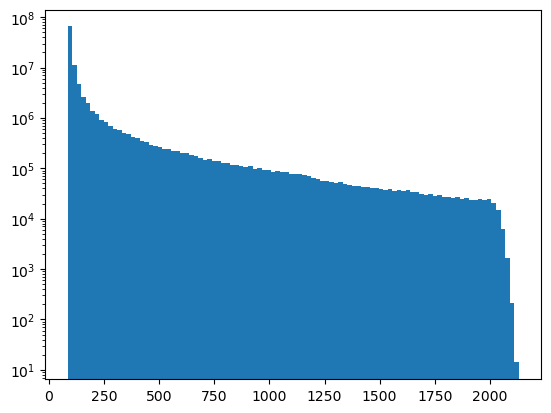

In [25]:
plt.hist(img.flatten(),bins=100)
plt.yscale('log')

Text(0.5, 1.0, 'SuperPosition')

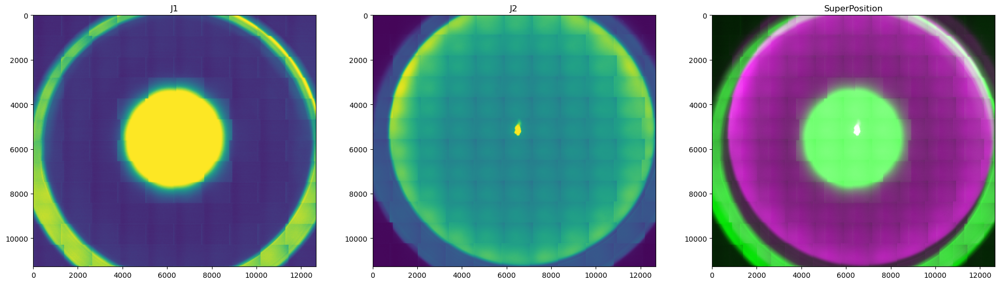

In [10]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_j2 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils_20260421\Mofibrils_A5\MofibrilsA5_t1\MofibrilA5t1_.czi")
img_j1 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils_20260421\Mofibrils_A5\MofibrilsA5_t0\MofibrilA5t0_.czi")
fig,ax = plt.subplots(1,3,figsize=(24,8))
img_j2 = normalize_2(img_j2.data[0,0,0,1000:,500:],high=99.9)
img_j1 = normalize_2(img_j1.data[0,0,0],high=90)

shape = min(img_j1.shape[0],img_j2.shape[0]),min(img_j1.shape[1],img_j2.shape[1])
img_j1 = img_j1[:shape[0],:shape[1]]
img_j2 = img_j2[:shape[0],:shape[1]]
ax[0].imshow(img_j1)
ax[0].set_title("J1")
ax[1].imshow(img_j2)
ax[1].set_title("J2")
ax[2].imshow(np.dstack([img_j2,img_j1,img_j2]))
ax[2].set_title("SuperPosition")

Text(0.5, 1.0, 'SuperPosition')

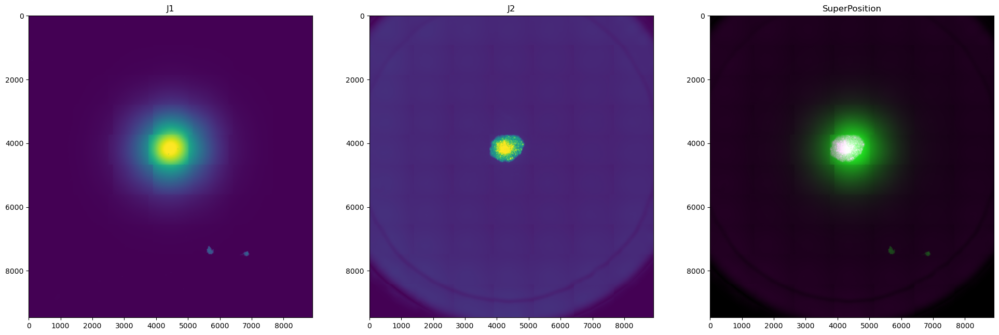

In [ ]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_j2 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\041726\Experiment-2735.czi")
img_j1 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\04152026\Experiment-2735.czi")
fig,ax = plt.subplots(1,3,figsize=(24,8))
img_j2 = normalize_2(img_j2.data[0,0,0],high=99.9)
img_j1 = normalize_2(img_j1.data[0,0,0],high=99.9)


ax[0].imshow(img_j1)
ax[0].set_title("J1")
ax[1].imshow(img_j2)
ax[1].set_title("J2")
ax[2].imshow(np.dstack([img_j2,img_j1,img_j2]))
ax[2].set_title("SuperPosition")

Text(0.5, 1.0, 'SuperPosition')

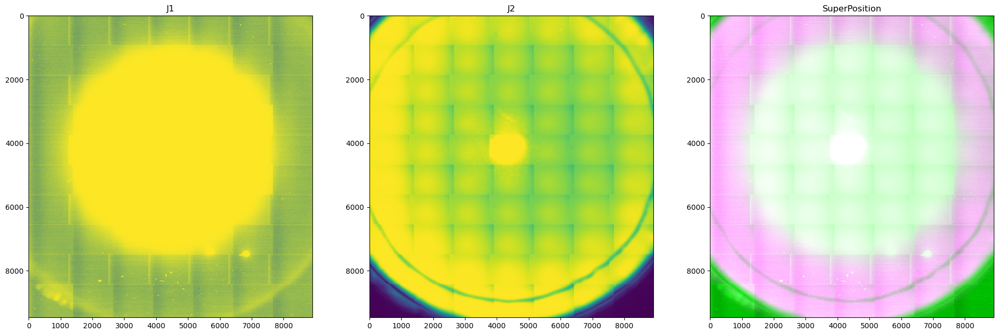

In [35]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_j2 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\041726\Experiment-2735.czi")
img_j1 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Fibres_hydrogel\04152026\Experiment-2735.czi")
fig,ax = plt.subplots(1,3,figsize=(24,8))
img_j2 = normalize_2(img_j2.data[0,0,0],high=80)
img_j1 = normalize_2(img_j1.data[0,0,0],high=40)


ax[0].imshow(img_j1)
ax[0].set_title("J1")
ax[1].imshow(img_j2)
ax[1].set_title("J2")
ax[2].imshow(np.dstack([img_j2,img_j1,img_j2]))
ax[2].set_title("SuperPosition")

In [1]:
3+3

6

Sum Pixels J1: 109.26451693538826
Sum Pixels J2: 108.88934127648997
Sum Pixels J3: 108.78432971705645


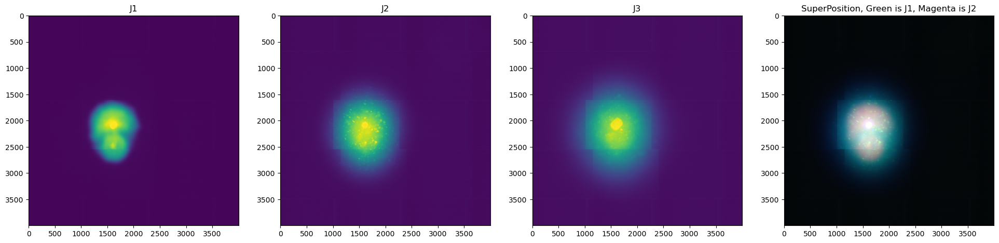

In [2]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_j1 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\billes 100nm integ50ms\billes t0\Experiment-2742(1).czi")
img_j2 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\billes 100nm integ50ms\billes t24h\billes t24h(1).czi")
img_j3 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\billes 100nm integ50ms\billes t48h\billes t48(1).czi")
print("Sum Pixels J1:",np.sum(img_j1.data)/np.prod(img_j1.shape))
print("Sum Pixels J2:",np.sum(img_j2.data)/np.prod(img_j2.shape))
print("Sum Pixels J3:",np.sum(img_j3.data)/np.prod(img_j3.shape))
fig,ax = plt.subplots(1,4,figsize=(24,8))
img_j1 = img_j1.data[0,0,0,4000:8000,4000:8000]
img_j2 = img_j2.data[0,0,0,4000:8000,4000:8000]
img_j3 = img_j3.data[0,0,0,4000:8000,4000:8000]
norm_j3 = normalize_2(img_j3,high=99.9)
norm_j2 = normalize_2(img_j2,high=99.9)
norm_j1 = normalize_2(img_j1,high=99.9)

stack = np.dstack([norm_j1,norm_j2,norm_j3])
ax[0].imshow(norm_j1)
ax[0].set_title("J1")
ax[1].imshow(norm_j2)
ax[1].set_title("J2")
ax[2].imshow(norm_j3)
ax[2].set_title("J3")
ax[3].imshow(stack)
_ = ax[3].set_title("SuperPosition, Green is J1, Magenta is J2")

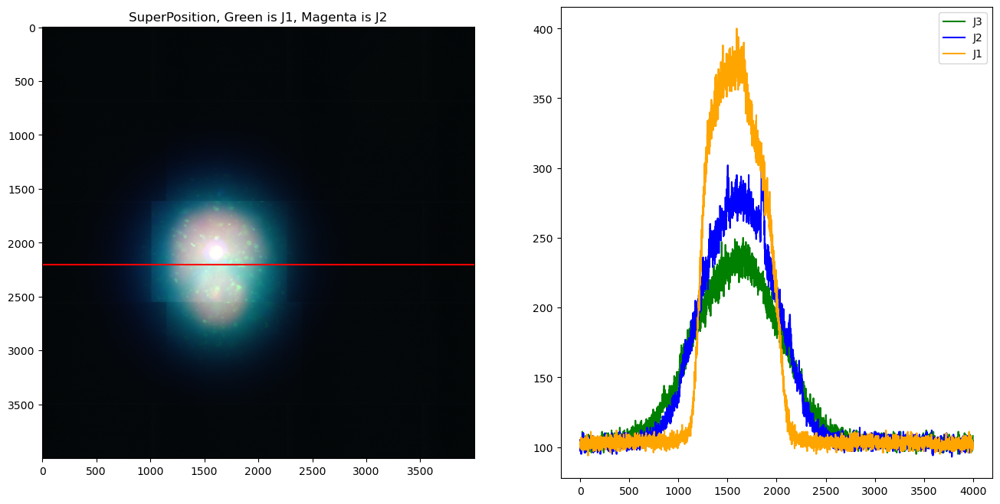

In [3]:
line_pos = 2200
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(stack)
ax[0].hlines(line_pos,xmin=1,xmax=stack.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J1, Magenta is J2")
ax[1].plot(img_j3[line_pos],label='J3',c='green')
ax[1].plot(img_j2[line_pos],label='J2',c='blue')
ax[1].plot(img_j1[line_pos],label='J1',c='orange')
ax[1].legend()

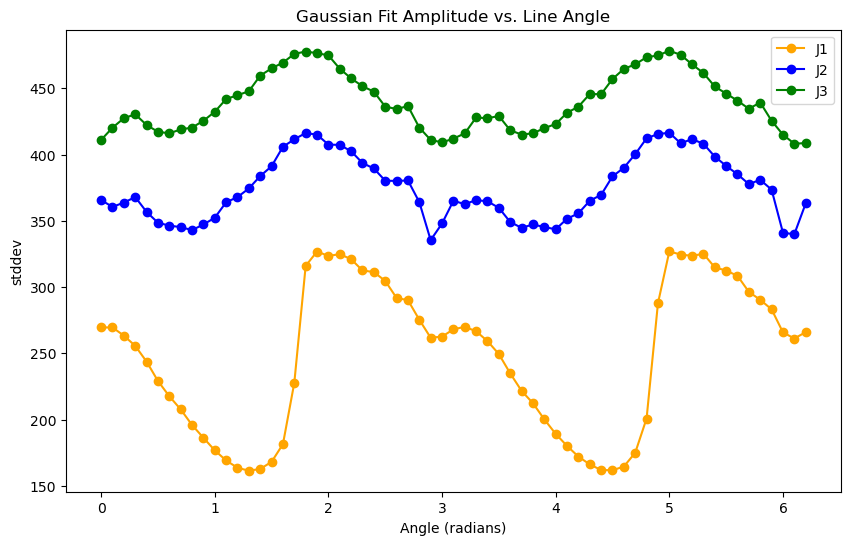

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates

# 1. Define the 1D Gaussian function for fitting
def gaussian(x, amplitude, mean, stddev, offset):
    return amplitude * np.exp(-((x - mean) ** 2) / (2 * stddev ** 2)) + offset

# Group the images for easier looping
images = [img_j1, img_j2, img_j3]
image_names = ['J1', 'J2', 'J3']

# 2. Define the center of the rotation and line lengths
# Assuming all images have the same shape, and you want to rotate around their center.
# Adjust cx, cy if your rotation center is different!
h, w = images[0].shape
cy, cx = h // 2, w // 2

# Determine the radius of the line to extract (distance from center to edge)
max_radius = min(cx, cy)
r = np.arange(-max_radius, max_radius) # Spatial axis along the line 

# Angles from 0 to 2*pi with 0.1 step
angles = np.arange(0, 2 * np.pi, 0.1)

# Dictionary to store the results
fit_results = {name: [] for name in image_names}

# 3. Loop through angles and images
for angle in angles:
    # Calculate pixel coordinates along the line for this angle
    x_coords = cx + r * np.cos(angle)
    y_coords = cy + r * np.sin(angle)
    coords = np.vstack((y_coords, x_coords))
    
    for i, img in enumerate(images):
        # Extract intensity profile along the line using bilinear interpolation
        profile = map_coordinates(img, coords, order=1, mode='reflect')
        
        # Define initial guesses for the Gaussian fit
        # [amplitude, mean_position, standard_deviation, baseline_offset]
        p0 = [np.max(profile) - np.min(profile), 0, 10, np.min(profile)]
        
        try:
            # Fit the extracted profile to the Gaussian
            popt, pcov = curve_fit(gaussian, r, profile, p0=p0, maxfev=2000)
            
            fit_results[image_names[i]].append({
                'angle': angle,
                'amplitude': popt[0],
                'mean': popt[1],
                'stddev': np.abs(popt[2]),
                'offset': popt[3],
                # 'covariance': pcov # Optionally store covariance for errors
            })
        except RuntimeError:
            # If optimization fails to find a fit, log as NaN
            fit_results[image_names[i]].append({
                'angle': angle,
                'amplitude': np.nan, 'mean': np.nan, 'stddev': np.nan, 'offset': np.nan
            })
            print(f"Fit failed for {image_names[i]} at angle {angle:.2f}")

#=========================================================
# Example Visualization 
# (Plotting the fitted Amplitudes as a function of the angle)
#=========================================================

fig, ax = plt.subplots(figsize=(10, 6))

colors = {'J1': 'orange', 'J2': 'blue', 'J3': 'green'}

for name in image_names:
    angle_vals = [res['angle'] for res in fit_results[name]]
    amp_vals = [res['stddev'] for res in fit_results[name]]
    
    ax.plot(angle_vals, amp_vals, marker='o', label=name, color=colors[name])

ax.set_title("Gaussian Fit Amplitude vs. Line Angle")
ax.set_xlabel("Angle (radians)")
ax.set_ylabel("stddev")
ax.legend()
plt.show()


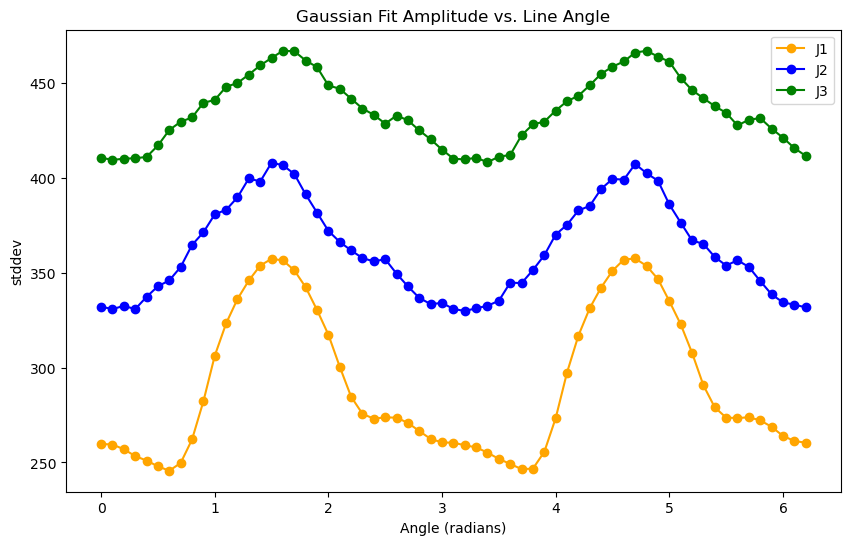

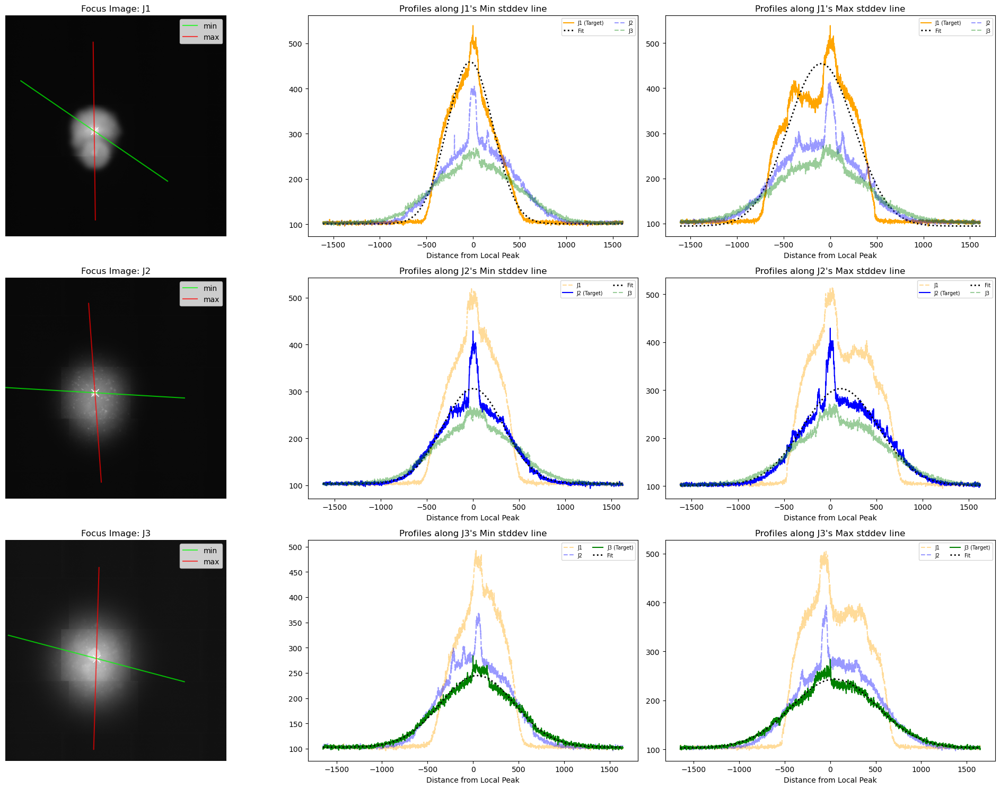

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates

# 1. Define the 1D Gaussian function and extraction helper
def gaussian(x, amplitude, mean, stddev, offset):
    return amplitude * np.exp(-((x - mean) ** 2) / (2 * stddev ** 2)) + offset

def get_profile(img, angle, cx, cy, r):
    x_coords = cx + r * np.cos(angle)
    y_coords = cy + r * np.sin(angle)
    coords = np.vstack((y_coords, x_coords))
    return map_coordinates(img, coords, order=1, mode='reflect')

# Data Setup
images = [img_j1, img_j2, img_j3]
image_names = ['J1', 'J2', 'J3']
colors = {'J1': 'orange', 'J2': 'blue', 'J3': 'green'}
angles = np.arange(0, 2 * np.pi, 0.1)

fit_results = {name: [] for name in image_names}
centers = {}

# 2. Analysis: Find peak-centers and perform fits
for i, img in enumerate(images):
    name = image_names[i]
    cy_max, cx_max = np.unravel_index(np.argmax(img), img.shape)
    centers[name] = (cy_max, cx_max)
    
    r_max = min(cx_max, cy_max, img.shape[1]-1-cx_max, img.shape[0]-1-cy_max)
    r_axis = np.arange(-r_max, r_max)
    
    for angle in angles:
        profile = get_profile(img, angle, cx_max, cy_max, r_axis)
        p0 = [np.max(profile) - np.min(profile), 0, 10, np.min(profile)]
        try:
            popt, _ = curve_fit(gaussian, r_axis, profile, p0=p0, maxfev=2000)
            fit_results[name].append({
                'angle': angle, 'amplitude': popt[0], 'mean': popt[1],
                'stddev': np.abs(popt[2]), 'offset': popt[3], 'r_axis': r_axis
            })
        except:
            fit_results[name].append({
                'angle': angle, 'amplitude': np.nan, 'stddev': np.nan
            })
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'J1': 'orange', 'J2': 'blue', 'J3': 'green'}

for name in image_names:
    angle_vals = [res['angle'] for res in fit_results[name]]
    amp_vals = [res['stddev'] for res in fit_results[name]]
    
    ax.plot(angle_vals, amp_vals, marker='o', label=name, color=colors[name])

ax.set_title("Gaussian Fit Amplitude vs. Line Angle")
ax.set_xlabel("Angle (radians)")
ax.set_ylabel("stddev")
ax.legend()
plt.show()

# 3. Enhanced Visualization
fig, axes = plt.subplots(len(image_names), 3, figsize=(20, 5 * len(image_names)))

for idx, name in enumerate(image_names):
    res_list = fit_results[name]
    cy, cx = centers[name]
    
    # Identify best/worst fit angles for THIS image
    stddevs = np.array([r.get('stddev', np.nan) for r in res_list])
    valid = ~np.isnan(stddevs)
    idx_min = np.where(valid)[0][np.argmin(stddevs[valid])]
    idx_max = np.where(valid)[0][np.argmax(stddevs[valid])]
    
    # Column 0: Image with Lines
    axes[idx, 0].imshow(images[idx], cmap='gray')
    axes[idx, 0].plot(cx, cy, 'wx', markersize=10)
    for r_idx, col,label in [(idx_min, 'lime','min'), (idx_max, 'red','max')]:
        r_res = res_list[r_idx]
        line_r = np.array([r_res['r_axis'][0], r_res['r_axis'][-1]])
        axes[idx, 0].plot(cx + line_r * np.cos(r_res['angle']), 
                          cy + line_r * np.sin(r_res['angle']), color=col, alpha=0.7,label=label)
    axes[idx, 0].set_title(f"Focus Image: {name}")
    axes[idx, 0].axis('off')
    axes[idx,0].legend()

    # Column 1 & 2: Overlaid Intensity Profiles
    for col_idx, center_idx, line_label in [(1, idx_min, 'Min'), (2, idx_max, 'Max')]:
        ax = axes[idx, col_idx]
        target_res = res_list[center_idx]
        curr_angle = target_res['angle']
        curr_r = target_res['r_axis']
        
        # Plot all J's along this specific line (of the current row's J)
        for other_idx, other_name in enumerate(image_names):
            other_prof = get_profile(images[other_idx], curr_angle, cx, cy, curr_r)
            
            is_target = (other_name == name)
            ln = ax.plot(curr_r, other_prof, 
                         color=colors[other_name], 
                         linestyle='-' if is_target else '--',
                         alpha=1.0 if is_target else 0.4,
                         label=f"{other_name}" + (" (Target)" if is_target else ""))
            
            if is_target:
                # Add fit line for target
                fit = gaussian(curr_r, target_res['amplitude'], target_res['mean'], target_res['stddev'], target_res['offset'])
                ax.plot(curr_r, fit, 'k:', linewidth=2, label='Fit')

        ax.set_title(f"Profiles along {name}'s {line_label} stddev line")
        ax.legend(fontsize='x-small', ncol=2)
        ax.set_xlabel("Distance from Local Peak")

plt.tight_layout()
plt.show()


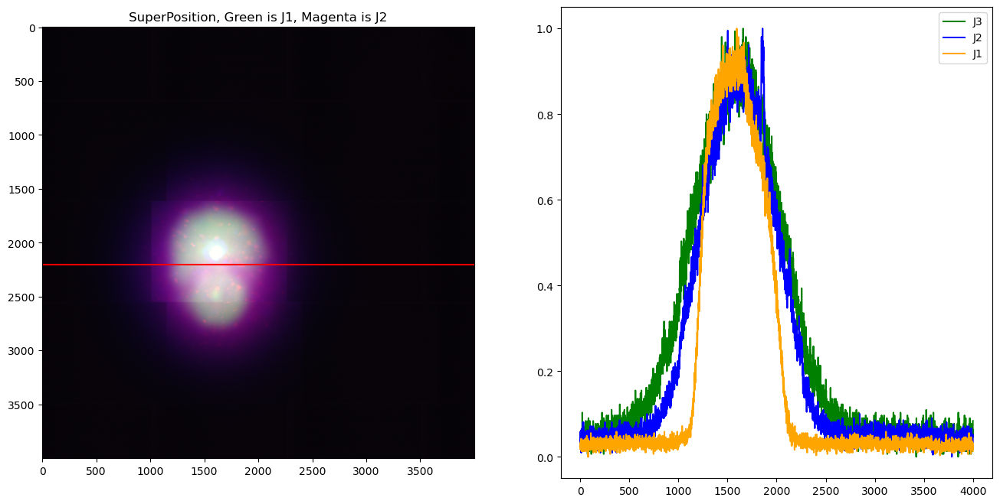

In [46]:
line_pos = 2200
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(stack)
ax[0].hlines(line_pos,xmin=1,xmax=stack.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J1, Magenta is J2")
ax[1].plot(norm_plot(img_j3[line_pos]),label='J3',c='green')
ax[1].plot(norm_plot(img_j2[line_pos]),label='J2',c='blue')
ax[1].plot(norm_plot(img_j1[line_pos]),label='J1',c='orange')
ax[1].legend()

Sum Pixels J1: 120.91244345218446
Sum Pixels J2: 121.8075582700652


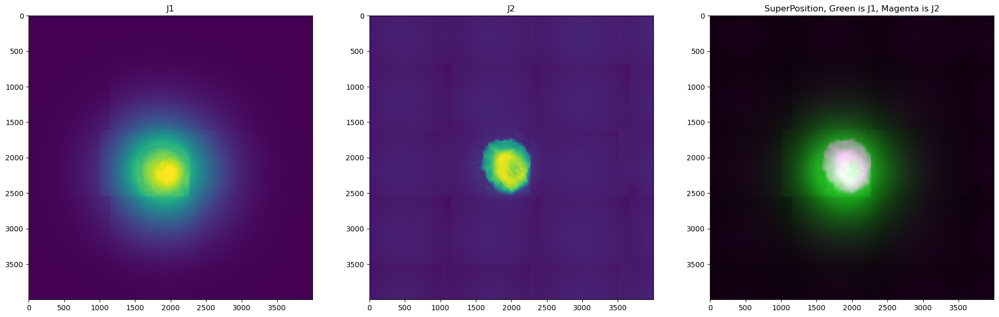

In [49]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_j1 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrils t0 5ms\Experiment-2743(1).czi")
img_j2 = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrilles t24h 5ms\mofibrilst24h5ms(1).czi")
print("Sum Pixels J1:",np.sum(img_j1.data)/np.prod(img_j1.shape))
print("Sum Pixels J2:",np.sum(img_j2.data)/np.prod(img_j2.shape))
fig,ax = plt.subplots(1,3,figsize=(24,8))
img_j1 = img_j1.data[0,0,0,4000:8000,4000:8000]
img_j2 = img_j2.data[0,0,0,4000:8000,4000:8000]
norm_j2 = normalize_2(img_j2,high=99.9)
norm_j1 = normalize_2(img_j1,high=99.9)

stack = np.dstack([norm_j2,norm_j1,norm_j2])
ax[0].imshow(norm_j1)
ax[0].set_title("J1")
ax[1].imshow(norm_j2)
ax[1].set_title("J2")
ax[2].imshow(stack)
_ = ax[2].set_title("SuperPosition, Green is J1, Magenta is J2")

In [50]:
def norm_plot(line):
    return (line-line.min())/(line.max()-line.min())

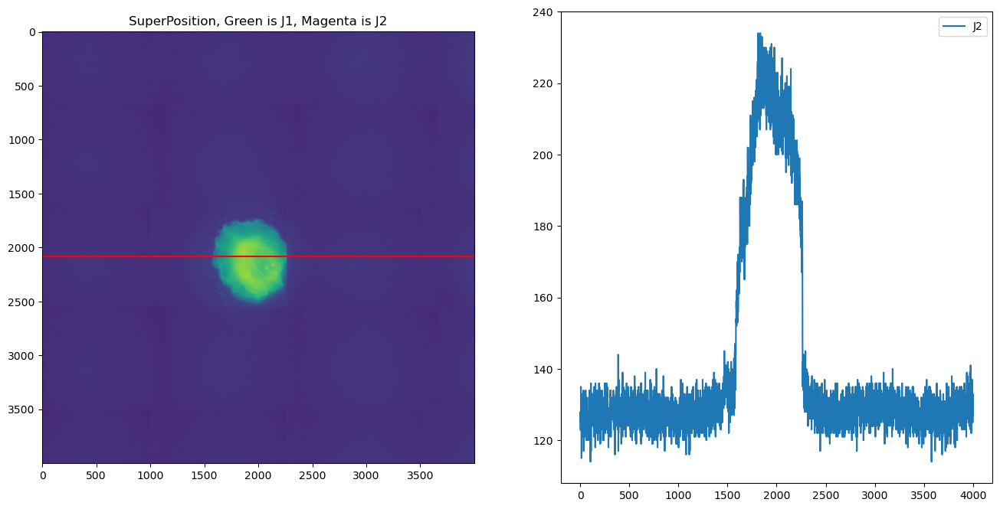

In [65]:
line_pos = 2080
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(img_j2)
ax[0].hlines(line_pos,xmin=1,xmax=img_j2.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J1, Magenta is J2")
ax[1].plot(img_j2[line_pos],label='J2')
# ax[1].plot(img_j1[line_pos],label='J1')
ax[1].legend()

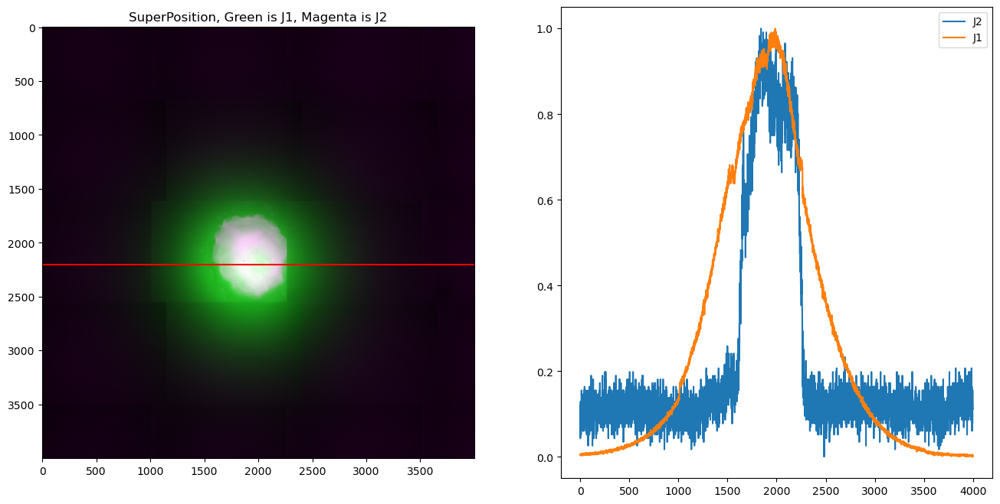

In [ ]:
line_pos = 2200
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(stack)
ax[0].hlines(line_pos,xmin=1,xmax=stack.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J1, Magenta is J2")
ax[1].plot(norm_plot(img_j2[line_pos]),label='J2')
ax[1].plot(norm_plot(img_j1[line_pos]),label='J1')
ax[1].legend()

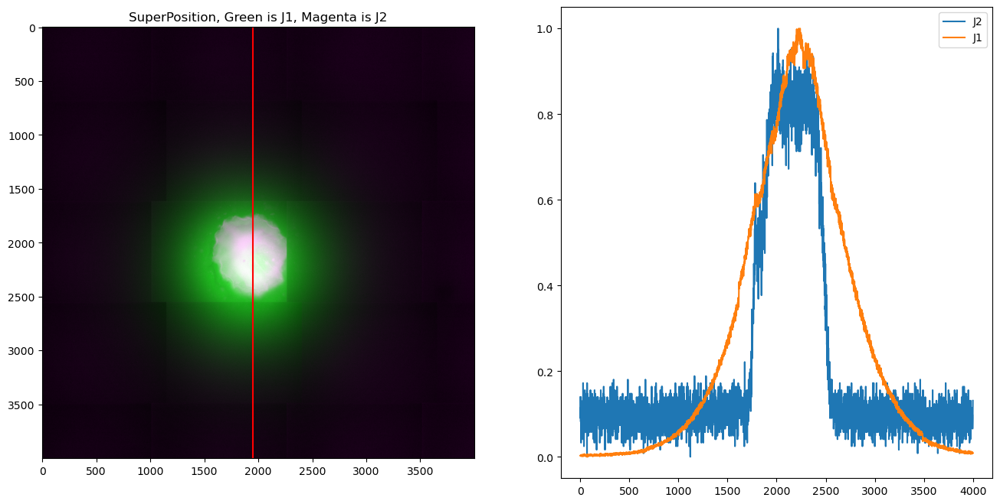

In [36]:
line_pos = 1950
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(stack)
ax[0].vlines(line_pos,ymin=1,ymax=stack.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J1, Magenta is J2")
ax[1].plot(norm_plot(img_j2[:,line_pos]),label='J2')
ax[1].plot(norm_plot(img_j1[:,line_pos]),label='J1')
ax[1].legend()

In [76]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrils t0 5ms\Experiment-2743(1).czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

shape = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrils t0 5ms\Experiment-2743(1).czi",
    reconstruct_mosaic=True,
    include_subblock_metadata=True,
    use_aicspylibczi=True
).data.shape
print(img.data.shape,shape)

(117, 1, 1, 1, 1040, 1392) (1, 1, 1, 12272, 11414)


Calculated Grid Shape: 13 rows x 9 cols = 117 tiles


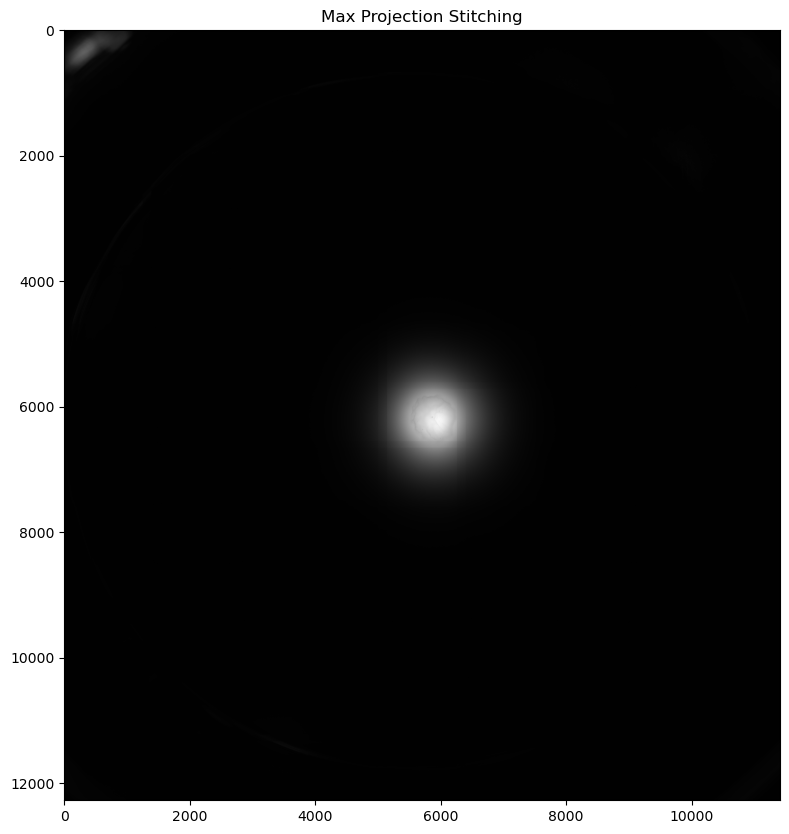

In [ ]:
import numpy as np
def stitch_projection(data, grid_shape, overlap=0.10, snake=False, method='max'):
    """
    Stitch M tiles with either a max or blend (average) projection in overlapping regions.
    
    Parameters:
    - data: numpy array of shape (M, 1, 1, 1, X, Y)
    - grid_shape: tuple of (rows, cols) specifying the grid layout of the tiles
    - overlap: float, fraction of overlap (e.g., 0.1 for 10% overlap in each direction)
    - snake: boolean, set to True if the microscope acquired tiles in a zigzag/snake pattern
    - method: str, 'max' or 'blend'. 'max' takes the maximum pixel value from overlapping tiles,
              'blend' averages the overlapping pixel values.
    
    Returns:
    - stitched_img: 2D numpy array containing the combined image casted to original dtype
    """
    if method not in ['max', 'blend']:
        raise ValueError("method must be 'max' or 'blend'")
        
    M, _, _, _, X, Y = data.shape
    rows, cols = grid_shape
    
    if rows * cols != M:
        print(f"Warning: grid_shape {(rows, cols)} does not equal number of tiles M={M}")
        
    # Calculate step sizes based on 10% overlap (step size is 90% in each direction)
    step_x = int(X * (1 - overlap))
    step_y = int(Y * (1 - overlap))
    
    # Calculate the ultimate dimensions of the output stitched image
    out_X = X + (rows - 1) * step_x
    out_Y = Y + (cols - 1) * step_y
    
    # Initialize the output arrays
    # Using float64 to prevent any overflow when summing image values in 'blend' mode
    stitched_img = np.zeros((out_X, out_Y), dtype=np.float64)
    
    # If blending, we need to track how many times a pixel gets added together 
    if method == 'blend':
        counts = np.zeros((out_X, out_Y), dtype=np.uint8)
    
    for i in range(M):
        # Determine the grid index (row and column) for the i-th tile
        r = i // cols
        c = i % cols
        
        # Adjust column index if a snake (zigzag) acquisition pattern was used
        if snake and r % 2 == 1:
            c = cols - 1 - c
            
        start_x = r * step_x
        start_y = c * step_y
        end_x = start_x + X
        end_y = start_y + Y
        
        # Extract the current 2D tile
        tile = data[i, 0, 0, 0, :, :]
        
        if method == 'max':
            # Apply max projection exactly over the overlapping regions
            stitched_img[start_x:end_x, start_y:end_y] = np.maximum(
                stitched_img[start_x:end_x, start_y:end_y],
                tile
            )
        elif method == 'blend':
            # Accumulate sum for blending
            stitched_img[start_x:end_x, start_y:end_y] += tile
            counts[start_x:end_x, start_y:end_y] += 1
    if method == 'blend':
        # Avoid division by zero in any strictly empty areas
        counts[counts == 0] = 1
        # Divide accumulated sum by the number of contributing tiles
        stitched_img = stitched_img / counts
        
    # Cast back and return using the original image data type (e.g. uint8 or uint16)
    return stitched_img.astype(data.dtype)

# --- Example of How to Call it --- #
# Suppose M is a 5x4 grid = 20 total tiles. Just update the grid_shape accurately.
# (If you don't know the rows and cols, you can compute them if the grid is square).
def get_grid_shape(M):
    """Finds the most square-like rectangular grid dimensions for M tiles."""
    factors = [(i, M // i) for i in range(1, int(np.sqrt(M)) + 1) if M % i == 0]
    if not factors:
        return (M, 1) # Fallback to 1D
    # Returns the pair closest to each other
    return factors[-1] 

# Example usage with your 117 tiles:
M = 117
cols, rows = get_grid_shape(M)
print(f"Calculated Grid Shape: {rows} rows x {cols} cols = {rows * cols} tiles")

# If it turns out it's rotated, you can just manually swap them:
# rows, cols = cols, rows

# stitched = stitch_max_projection(img.data, grid_shape=(rows, cols), overlap=0.10)



(117, 1, 1, 1, 1040, 1392) (1, 1, 1, 12272, 11414)


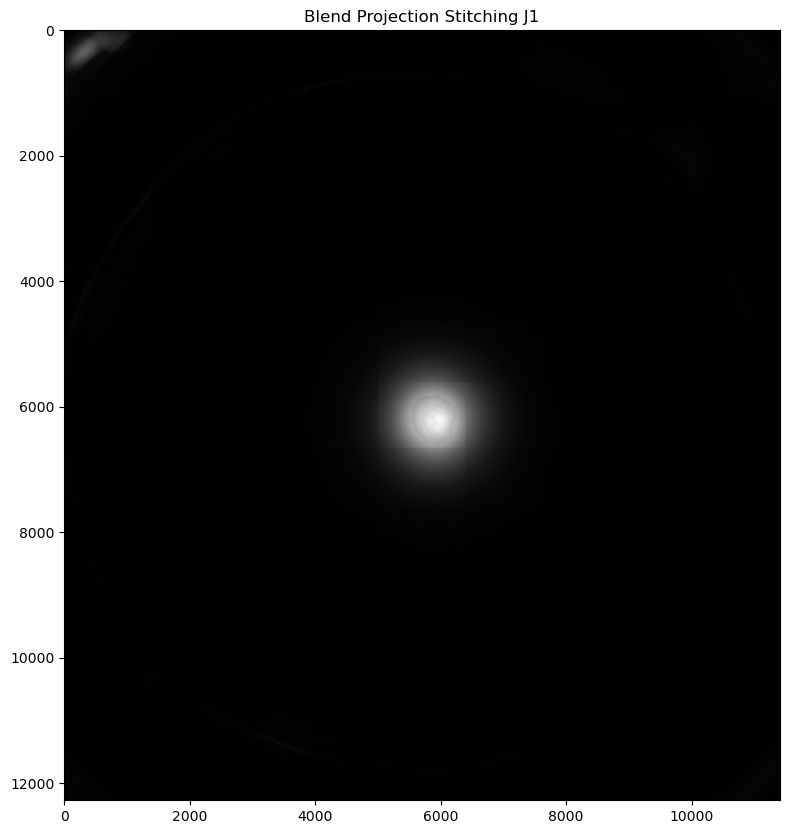

In [95]:
import numpy as np
from bioio import BioImage
import matplotlib.pyplot as plt
from skimage.exposure import rescale_intensity
def normalize_2(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrils t0 5ms\Experiment-2743(1).czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

shape = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrils t0 5ms\Experiment-2743(1).czi",
    reconstruct_mosaic=True,
    include_subblock_metadata=True,
    use_aicspylibczi=True
).data.shape
print(img.data.shape,shape)
img_t0 = stitch_projection(img.data, grid_shape=(rows, cols), overlap=0.10, snake=True,method='max')

plt.figure(figsize=(10, 10))
plt.imshow(img_t0, cmap='gray')
plt.title("Blend Projection Stitching J1")
plt.show()


(117, 1, 1, 1, 1040, 1392) (1, 1, 1, 12272, 11414)


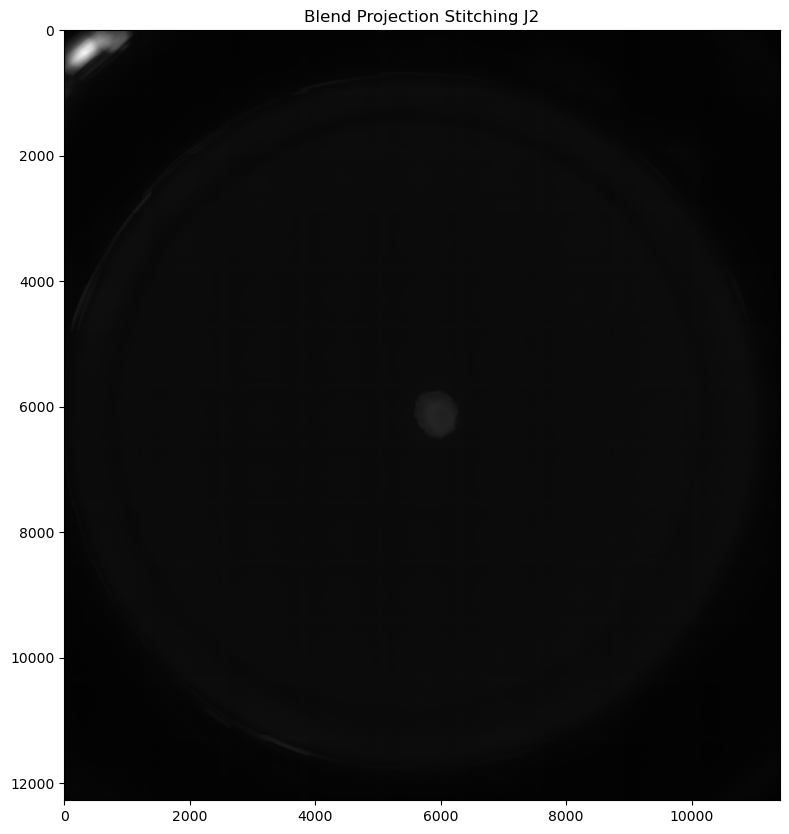

In [96]:
img = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrilles t24h 5ms\mofibrilst24h5ms(1).czi",
    reconstruct_mosaic=False,
    include_subblock_metadata=True,
    use_aicspylibczi=True
)

shape = BioImage(r"C:\Users\Emman\Desktop\work\These\Data\Human\Mofibrils 20260419\Mofibrilles t24h 5ms\mofibrilst24h5ms(1).czi",
    reconstruct_mosaic=True,
    include_subblock_metadata=True,
    use_aicspylibczi=True
).data.shape
print(img.data.shape,shape)
img_t1 = stitch_projection(img.data, grid_shape=(rows, cols), overlap=0.10, snake=True,method='max')

plt.figure(figsize=(10, 10))
plt.imshow(img_t1, cmap='gray')
plt.title("Blend Projection Stitching J2")
plt.show()


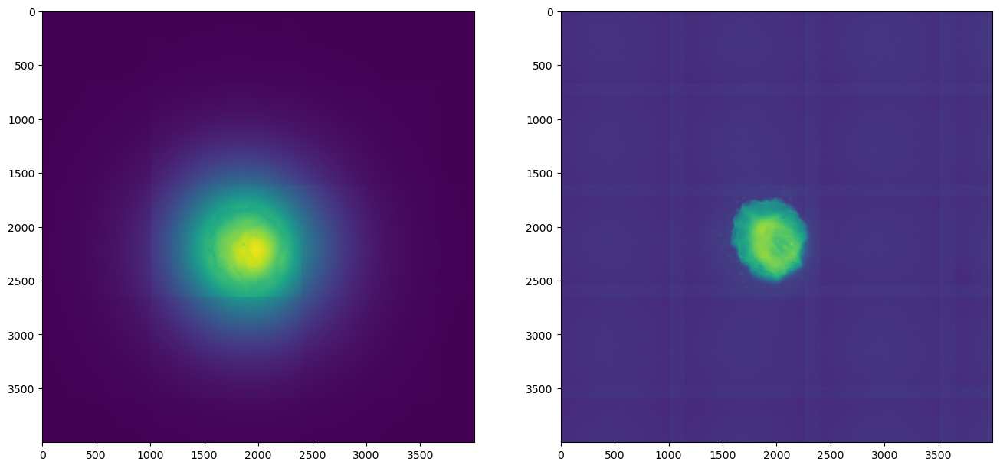

In [97]:
img_t1 = img_t1[4000:8000,4000:8000]
img_t0 = img_t0[4000:8000,4000:8000]
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(img_t0)
ax[1].imshow(img_t1)

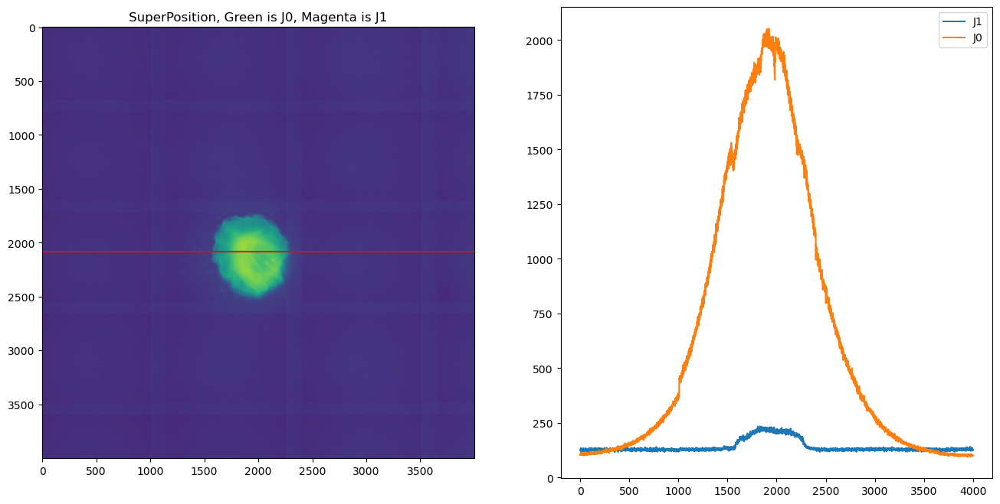

In [98]:
line_pos = 2080
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(img_t1)
ax[0].hlines(line_pos,xmin=1,xmax=img_t1.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J0, Magenta is J1")
ax[1].plot(img_t1[line_pos],label='J1')
ax[1].plot(img_t0[line_pos],label='J0')
ax[1].legend()

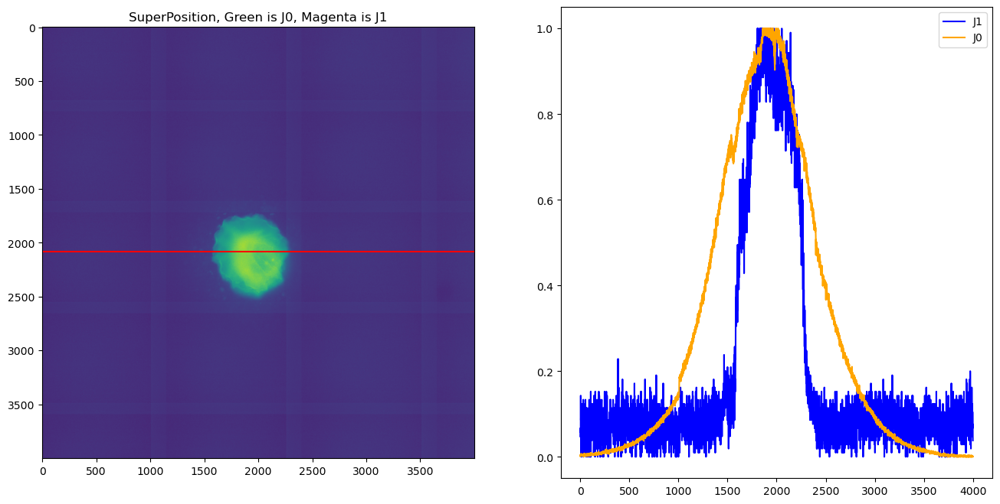

In [101]:
line_pos = 2080
fig,ax = plt.subplots(1,2,figsize=(16,8))
ax[0].imshow(img_t1)
ax[0].hlines(line_pos,xmin=1,xmax=img_t1.shape[0]-1,color='r')
ax[0].set_title("SuperPosition, Green is J0, Magenta is J1")
ax[1].plot(normalize_2(img_t1[line_pos]),label='J1',c='b')
ax[1].plot(normalize_2(img_t0[line_pos]),label='J0',c='orange')
ax[1].legend()

In [112]:
import numpy as np
import plotly.graph_objects as go

def plot_image_3d_plotly(img, downsample=5, colorscale='Viridis'):
    """
    Plots a 2D image in 3D using Plotly for interactivity.
    
    Parameters:
    - img: 2D numpy array
    - downsample: factor to reduce resolution (higher = faster rendering)
    - colorscale: 'Viridis', 'Cividis', 'Hot', 'Magma', etc.
    """
    # Downsample for performance
    z_data = img[::downsample, ::downsample]
    
    # Create the surface plot
    fig = go.Figure(data=[go.Surface(z=z_data, colorscale=colorscale)])

    # Update layout to add titles and maintain aspect ratio
    fig.update_layout(
        title='Interactive Intensity Surface Projection',
        autosize=True,
        width=900,
        height=800,
        scene=dict(
            xaxis_title='X (Pixels)',
            yaxis_title='Y (Pixels)',
            zaxis_title='Intensity',
            aspectmode='manual',
            aspectratio=dict(x=1, y=1, z=0.5) # Flattens the Z axis slightly for better viewing
        ),
        margin=dict(l=65, r=50, b=65, t=90)
    )

    fig.show()

# Usage:
plot_image_3d_plotly(img_t1, downsample=10)
# Usage:
plot_image_3d_plotly(img_t0, downsample=10)



In [113]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def plot_dual_image_3d(img0, img1, downsample=10, names=('T0', 'T1')):
    """
    Visualizes two 3D intensity surfaces side-by-side in one figure.
    """
    # Downsample for performance
    z0 = img0[::downsample, ::downsample]
    z1 = img1[::downsample, ::downsample]
    
    # Create subplots: 1 row, 2 columns, both 'surface' type
    fig = make_subplots(
        rows=1, cols=2,
        specs=[[{'type': 'surface'}, {'type': 'surface'}]],
        subplot_titles=names
    )

    # Add the first timepoint (T0)
    fig.add_trace(
        go.Surface(z=z0, colorscale='Viridis', showscale=False),
        row=1, col=1
    )

    # Add the second timepoint (T1)
    fig.add_trace(
        go.Surface(z=z1, colorscale='Magma', showscale=False),
        row=1, col=2
    )

    # Update layout to handle both 3D scenes
    fig.update_layout(
        title_text='Timepoint Comparison: Intensity Surfaces',
        width=1200,
        height=700,
        margin=dict(l=0, r=0, b=0, t=80),
        scene1=dict(
            xaxis_title='X', yaxis_title='Y', zaxis_title='Intensity',
            aspectratio=dict(x=1, y=1, z=0.4)
        ),
        scene2=dict(
            xaxis_title='X', yaxis_title='Y', zaxis_title='Intensity',
            aspectratio=dict(x=1, y=1, z=0.4)
        )
    )

    fig.show()

# Usage:
plot_dual_image_3d(img_t0, img_t1, downsample=10)


In [106]:
# Calculate R-squared
# Predicted Y values based on the fit
Y_pred = m * X + c

# Residual sum of squares
ss_res = np.sum((Y - Y_pred)**2)

# Total sum of squares
ss_tot = np.sum((Y - np.mean(Y))**2)

r_squared = 1 - (ss_res / ss_tot)

print(f"R² Value: {r_squared:.5f}")


R² Value: 0.99906


In [ ]:
R² Value: 0.9990

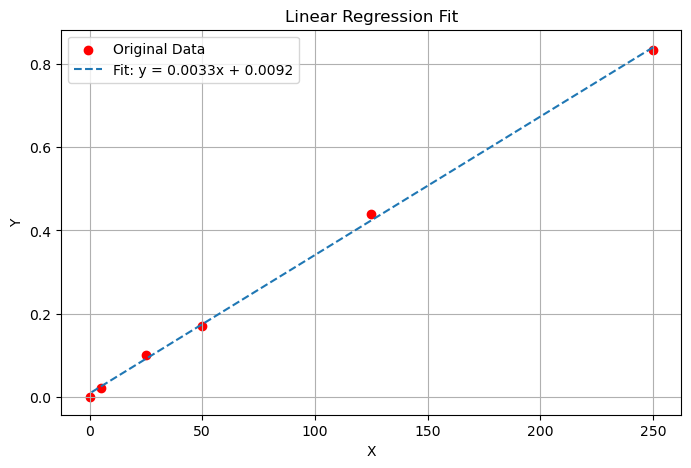

Regression Equation: Y = 0.00332*X + 0.00915
------------------------------
X values for the first set:
[ 64.0901897   91.79196442 121.90258911 127.92471405  64.99350844
  77.03775832  94.80302689  83.963202  ]

X values for the second set:
[112.56829546  82.75877701  51.44372733  73.12337711  86.37205198
  75.83333333  68.00457091  95.10413314]


In [105]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the data
X = np.array([250, 125, 50, 25, 5, 0])
Y = np.array([0.832, 0.439, 0.171, 0.102, 0.022, 0])

# 2. Fit with linear regression (degree 1)
# slope (m) and intercept (c)
m, c = np.polyfit(X, Y, 1)

# 3. Plot the original data and the regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='red', label='Original Data')
plt.plot(X, m*X + c, '--', label=f'Fit: y = {m:.4f}x + {c:.4f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.title('Linear Regression Fit')
plt.grid(True)
plt.show()

# 4. Function to find X from Y using the inverse: X = (Y - intercept) / slope
def find_x(y_values, slope, intercept):
    return (np.array(y_values) - intercept) / slope

# New Y values to calculate
y1 = [0.222, 0.314, 0.414, 0.434, 0.225, 0.265, 0.324, 0.288]
y2 = [0.383, 0.284, 0.180, 0.252, 0.296, 0.261, 0.235, 0.325]

x1_result = find_x(y1, m, c)
x2_result = find_x(y2, m, c)

print(f"Regression Equation: Y = {m:.5f}*X + {c:.5f}")
print("-" * 30)
print("X values for the first set:")
print(x1_result)
print("\nX values for the second set:")
print(x2_result)


(array([2.000000e+00, 5.000000e+00, 6.000000e+00, 2.800000e+01,
        5.300000e+01, 3.470000e+02, 3.840000e+03, 5.586250e+05,
        5.597236e+06, 1.539186e+06]),
 array([   0. ,  302.4,  604.8,  907.2, 1209.6, 1512. , 1814.4, 2116.8,
        2419.2, 2721.6, 3024. ]),
 <BarContainer object of 10 artists>)

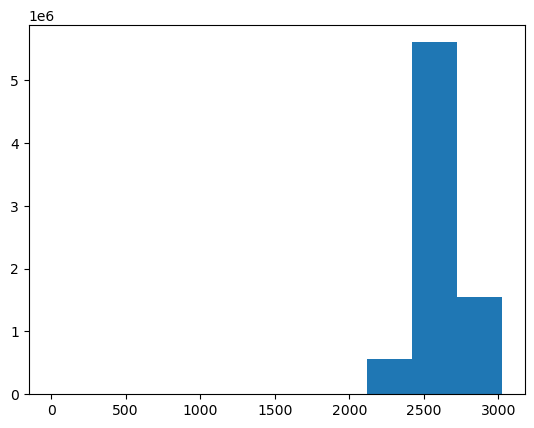

In [125]:
plt.hist(3024-img_temp[:,:,2].flatten())

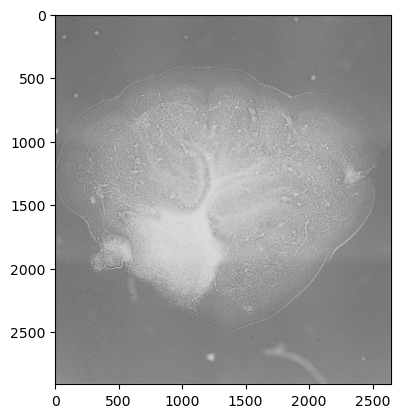

In [126]:
from skimage.io import imread
img_temp = imread(r"C:\Users\Emman\Desktop\work\These\Code\Stitcher\data\output\Fibres\090426\Tr1_Insert1.tiff")
plt.imshow(3024-img_temp[:,:,2],cmap='gray',vmin=2000)

In [ ]:
3+3
3+3

6

In [ ]:
import numpy as np

def stitch_tiles_serpentine(img, grid_shape=(3, 3), overlap=0.1):
    """
    Stitches tiles arranged in a serpentine pattern:
    Row 0: 0 -> 1 -> 2
    Row 1: 5 <- 4 <- 3
    Row 2: 6 -> 7 -> 8
    
    Parameters:
    - img: numpy array of shape (N_tiles, Channels, H, W)
    - grid_shape: Tuple (rows, cols), e.g., (3, 3)
    - overlap: Float, percentage of overlap (0.1 = 10%)
    """
    N, C, H, W = img.shape
    rows, cols = grid_shape
    
    # Calculate step size (how much to shift each tile)
    step_h = int(H * (1 - overlap))
    step_w = int(W * (1 - overlap))
    
    # Calculate final image dimensions
    full_h = H + (rows - 1) * step_h
    full_w = W + (cols - 1) * step_w
    
    # Initialize the canvas and a weight map (for averaging overlaps)
    stitched = np.zeros((C, full_h, full_w), dtype=np.float32)
    weights = np.zeros((full_h, full_w), dtype=np.float32)
    
    # Optional: You can use a ramp/mask here for smoother blending
    tile_mask = np.ones((H, W), dtype=np.float32)

    for r in range(rows):
        for c in range(cols):
            # Calculate the linear position in the 3x3 grid
            i = r * cols + c
            
            # Serpentine Logic:
            # Even rows (0, 2, ...): index increases (0, 1, 2)
            # Odd rows (1, 3, ...): index decreases (5, 4, 3)
            if r % 2 == 0:
                tile_idx = i
            else:
                row_start = r * cols
                row_end = (r + 1) * cols - 1
                tile_idx = row_end - (i - row_start)
            
            # Position on the final canvas
            y_start = r * step_h
            x_start = c * step_w
            
            # Add tile content and update weights
            stitched[:, y_start:y_start+H, x_start:x_start+W] += img[tile_idx] * tile_mask
            weights[y_start:y_start+H, x_start:x_start+W] += tile_mask
            
    # Normalize by weights to average the overlapping regions
    stitched /= np.maximum(weights, 1e-6)
    
    return stitched

In [26]:
import matplotlib.pyplot as plt
from bioio import BioImage
from skimage.exposure import rescale_intensity
import numpy as np

def norm(img, low= 1,high=99):
    return rescale_intensity(img, in_range=(np.percentile(img, low), np.percentile(img, high)), out_range=(0, 1))

img_path = r"C:\Users\Emman\Desktop\work\These\Data\Emmanuel\042426\2_concentrations_fibres\insert1_concentration_1\Insert_1_concentration1_042426(2).czi"
img = BioImage(img_path,
    reconstruct_mosaic=False,
    include_subblock_metadata=False,
    use_aicspylibczi=True
)

print(img.data.shape)
img = img.data.squeeze()

(9, 1, 3, 1, 1040, 1392)


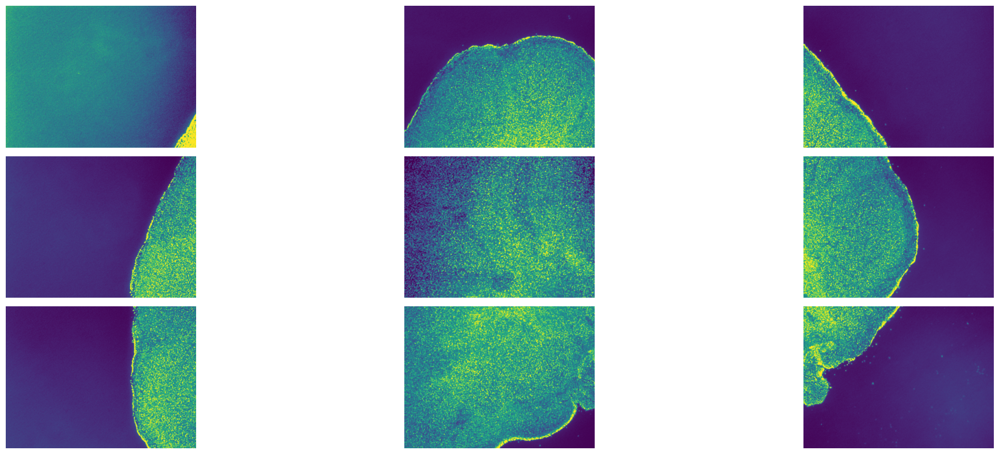

In [22]:
fig,ax = plt.subplots(3,3,figsize=(24,8))
ax = ax.ravel()
for i in range(9):
    if i<3 or i>5:
        ax[i].imshow(norm(img[i,0]))
    else:
        ax[i].imshow(norm(img[8-i,0]))
    ax[i].axis('off')
plt.tight_layout()

In [ ]:
# Example usage:
stitched_image = stitch_tiles_serpentine(img, grid_shape=(3, 3), overlap=0.1)

# To visualize channel 0:
plt.imshow(norm(stitched_image[0]), cmap='magma')

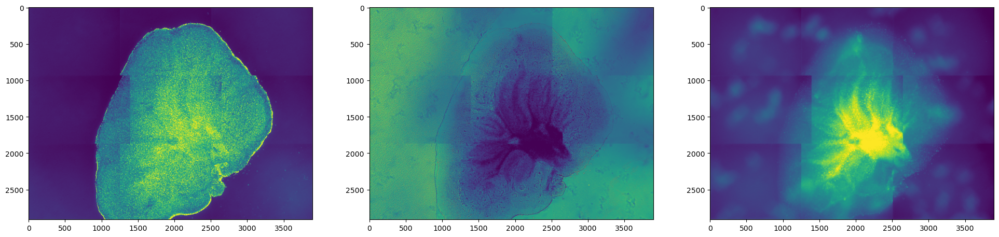

In [ ]:
# fig,ax = plt.subplots(1,3,figsize=(24,8))
# ax[0].imshow(norm(img[0]))
# ax[1].imshow(norm(img[1]))
# ax[2].imshow(norm(img[2]))